# Chapter 9 — Kernel Functions and the Representer Theorem

*Chapters 6 and 8 ended on the same observation: the dual form of ridge regression and the dual form of the support vector machine use the training examples only through their inner products. This chapter follows that observation to its conclusion. If we can compute the inner product of two feature vectors without ever building them, the feature space can be enormous, or even infinite-dimensional, and the cost of the method does not depend on its dimension. We shall characterize the functions that are inner products (the positive semidefinite kernels), prove the representer theorem, which says that the solution of a very large class of penalized problems is a combination of kernel functions centered at the training points, derive kernel ridge regression, use the SVM of Chapter 8 with the Gaussian kernel, and see how to approximate a kernel method when $n$ is too large for it.*

## 9.1 Learning objectives

Section 6.7 improved linear models by adding nonlinear features (all the monomials up to a given degree), and found a limit: the number of features grows quickly with the degree and with the number of inputs, and a fit with many features is a disaster without regularization. Section 6.7.2 and Chapter 8 showed that the computation can be moved to the dual, where the cost depends on $n$ and not on the number of features. The remaining step is to stop building the features at all.

After working through the chapter you will be able to:

1. define a **kernel** as an inner product in a feature space, and write the polynomial, Gaussian (RBF), Laplacian and linear kernels, together with the distances and angles that a kernel defines;
2. state and prove the **characterization of kernels** (a symmetric function is a kernel if and only if all its Gram matrices are positive semidefinite) and the **closure properties** (sums, products, exponentials), and use them to show that the Gaussian kernel has an infinite-dimensional feature space, which you can write explicitly in one dimension;
3. check numerically that a function is, or is not, a kernel, and explain what can go wrong with a function that is not (the dual problem is no longer convex);
4. define the **reproducing kernel Hilbert space** of a kernel, state and prove the **representer theorem**, and use it to turn a penalized problem over functions into a problem in $n$ coefficients;
5. derive **kernel ridge regression**, show that it reduces to the ridge regression of Chapter 6 for the linear kernel, prove the **leave-one-out shortcut** for it, and read the shrinkage of the eigenvalues of the Gram matrix as the shrinkage of the singular values of Section 6.3.2;
6. use the **kernel SVM** (the SMO of Section 8.5.2 works on any Gram matrix), tune $(C, \gamma)$ with the protocols of Chapter 5, and describe the three regimes of the bandwidth $\gamma$: a nearly linear model, a good fit, and memorization;
7. bound the generalization of a kernel classifier through the norm $\lVert f\rVert_{\mathcal{H}}$ and the radius $\sup_x\sqrt{k(x, x)}$ (Theorem 3.7 in the feature space);
8. approximate a kernel with **random Fourier features** (prove that they are unbiased and give a Hoeffding bound) or with the **Nyström method**, and say when the approximation is worth it.

**Prerequisites.** Chapters 1 to 8. In particular feature maps and the dual form of ridge regression (Sections 6.7.1 and 6.7.2), the singular-value view of ridge (Section 6.3.2) and its leave-one-out shortcut (Proposition 6.8), the margin and Rademacher bounds of Section 3.8, the dual of the SVM and the function `smo` (Sections 8.2 to 8.5), and the cross-validation protocols of Chapter 5. Linear algebra of symmetric positive semidefinite matrices (Section 2.3.7) is used throughout.

:::{admonition} A word about the data in this chapter
:class: note
The experiments use real data sets, all shipped with scikit-learn: **Iris** (the Gram matrices of Section 9.3), **Breast Cancer** (the stratified split of Chapters 6 to 8, 426 training and 143 test patients, malignant $= +1$), **Digits** (the stratified split of 1347 training and 450 test images) and **Diabetes** (the 331/111 split of Chapters 6 and 7). Only one example is not data: the three points of Worked example 9.1, small enough to be solved by hand. The features of the Breast Cancer data are standardized with the statistics of the training set, as in Chapter 8; for Digits we shall see that the *scale* of the features matters for kernels more than for linear models.
:::

### Setting up this notebook

As in the previous chapters, the next two cells print the versions of the libraries and define the plotting style and the random seed.

In [1]:
import platform
from importlib.metadata import version

print("Python", platform.python_version())
for pkg in ["numpy", "scipy", "pandas", "matplotlib", "scikit-learn"]:
    print(f"{pkg:<14}{version(pkg)}")

Python 3.15.2
numpy         2.5.5
scipy         1.18.1
pandas        3.1.1
matplotlib    3.11.2
scikit-learn  1.9.1


In [2]:
import time
import warnings
from math import factorial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from sklearn.datasets import load_breast_cancer, load_diabetes, load_digits, load_iris
from sklearn.exceptions import ConvergenceWarning
from sklearn.kernel_approximation import Nystroem, RBFSampler
from sklearn.kernel_ridge import KernelRidge
from sklearn.linear_model import Ridge
from sklearn.metrics.pairwise import laplacian_kernel, linear_kernel, polynomial_kernel, rbf_kernel, sigmoid_kernel
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC

warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42  # fixed seed: random operations give the same result every time

# Plotting style used throughout the book (Okabe-Ito colors, safe for color-vision deficiencies).
BLUE, ORANGE, GREEN = "#0072B2", "#E69F00", "#009E73"
VERMILION, SKY, PURPLE = "#D55E00", "#56B4E9", "#CC79A7"
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (6.4, 4.0),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})

## 9.2 From inner products to kernels

### 9.2.1 The idea

Three formulas that we already know have the same structure. The ridge regression of Section 6.7.2, written in the dual, predicts with $\hat f(\mathbf{x}) = \sum_i\alpha_i\,\boldsymbol\varphi(\mathbf{x}_i)^\top\boldsymbol\varphi(\mathbf{x})$ and $\boldsymbol\alpha = (\boldsymbol\Phi\boldsymbol\Phi^\top + \lambda\mathbf{I})^{-1}\mathbf{y}$. The soft-margin SVM of Theorem 8.4 maximizes $\sum_i\alpha_i - \frac12\sum_{i,j}\alpha_i\alpha_jy_iy_j\,\mathbf{x}_i^\top\mathbf{x}_j$ and predicts with $\operatorname{sign}\big(\sum_i\alpha_iy_i\,\mathbf{x}_i^\top\mathbf{x} + b\big)$. And the SMO algorithm of Section 8.5.2 touched the data only through the Gram matrix. In all of them, if the data are first mapped to feature vectors $\boldsymbol\phi(\mathbf{x})$, **the features enter only through the inner products $\boldsymbol\phi(\mathbf{x})^\top\boldsymbol\phi(\mathbf{z})$.**

:::{admonition} Definition 9.1 (kernel)
:class: tip
A function $k:\mathcal{X}\times\mathcal{X}\to\mathbb{R}$ is a **kernel** if there exist a real vector space $\mathcal{F}$ with an inner product $\langle\cdot,\cdot\rangle$ (a **feature space**, finite- or infinite-dimensional, complete) and a map $\boldsymbol\phi:\mathcal{X}\to\mathcal{F}$ such that
$$
k(\mathbf{x}, \mathbf{z}) = \langle\boldsymbol\phi(\mathbf{x}), \boldsymbol\phi(\mathbf{z})\rangle\qquad\text{for all }\mathbf{x}, \mathbf{z}.
$$
The **kernel trick** consists in replacing $\mathbf{x}_i^\top\mathbf{x}_j$ by $k(\mathbf{x}_i, \mathbf{x}_j)$ in an algorithm that uses the data only through inner products: the algorithm then runs in the feature space, without ever computing $\boldsymbol\phi$.
:::

The matrix $\mathbf{K}\in\mathbb{R}^{n\times n}$ with entries $K_{ij} = k(\mathbf{x}_i, \mathbf{x}_j)$ is the **Gram matrix** of the sample (the kernel matrix). The cost of a kernel method depends on $n$, through $\mathbf{K}$, and on the cost of evaluating $k$, but not on the dimension of $\mathcal{F}$. This is what makes it possible to use feature spaces of dimension $10^{5}$ or infinite. Here are the kernels that we shall use ($\gamma > 0$, $c\ge 0$ and the integer $p\ge 1$ are parameters):

| Kernel | $k(\mathbf{x}, \mathbf{z})$ | Feature space |
|---|---|---|
| Linear | $\mathbf{x}^\top\mathbf{z}$ | $\mathbb{R}^d$, $\boldsymbol\phi(\mathbf{x}) = \mathbf{x}$ |
| Polynomial | $(\gamma\,\mathbf{x}^\top\mathbf{z} + c)^p$ | all the monomials of degree $\le p$ (for $c > 0$): dimension $\binom{d + p}{p}$ |
| Gaussian (RBF) | $\exp(-\gamma\lVert\mathbf{x} - \mathbf{z}\rVert_2^2)$ | infinite-dimensional (Section 9.3.3) |
| Laplacian | $\exp(-\gamma\lVert\mathbf{x} - \mathbf{z}\rVert_1)$ | infinite-dimensional |

A kernel defines a geometry in the feature space *without* describing it. The squared norm of $\boldsymbol\phi(\mathbf{x})$ is $k(\mathbf{x}, \mathbf{x})$, and the squared distance between two images is $\lVert\boldsymbol\phi(\mathbf{x}) - \boldsymbol\phi(\mathbf{z})\rVert^2 = k(\mathbf{x}, \mathbf{x}) + k(\mathbf{z}, \mathbf{z}) - 2k(\mathbf{x}, \mathbf{z})$. For the Gaussian kernel $k(\mathbf{x}, \mathbf{x}) = 1$ for every $\mathbf{x}$: *all the images lie on the unit sphere of the feature space*, their squared distance is $2 - 2k(\mathbf{x}, \mathbf{z})\in[0, 2)$, and $k$ is the cosine of the angle between them, a **similarity** that goes from $1$ (the same point) to $0$ (very far apart). The parameter $\gamma$ is the inverse of the squared length scale: $k = e^{-1}$ at the distance $1/\sqrt\gamma$.

### Worked example 9.1 — kernel ridge regression with $k(x, z) = \min(x, z)$

The function $k(x, z) = \min(x, z)$ on $x, z > 0$ is a kernel (it is the covariance of the Brownian motion; Section 9.3 shows how to check this). *This three-point data set is constructed, to be solved by hand.* Take the points $x = 1, 2, 3$ with the responses $\mathbf{y} = (1, 3, 2)$. The Gram matrix is

$$
\mathbf{K} = \begin{pmatrix}1&1&1\\1&2&2\\1&2&3\end{pmatrix},
\qquad
\mathbf{K} + \mathbf{I} = \begin{pmatrix}2&1&1\\1&3&2\\1&2&4\end{pmatrix},
\qquad
(\mathbf{K} + \mathbf{I})^{-1} = \frac1{13}\begin{pmatrix}8&-2&-1\\-2&7&-3\\-1&-3&5\end{pmatrix}.
$$

(The determinant of $\mathbf{K} + \mathbf{I}$ is $13$.) The kernel ridge regression of Section 9.5, with penalty $\lambda = 1$, has coefficients $\boldsymbol\alpha = (\mathbf{K} + \mathbf{I})^{-1}\mathbf{y} = \frac1{13}(8 - 6 - 2,\ -2 + 21 - 6,\ -1 - 9 + 10) = (0, 1, 0)$, so the fitted function is $\hat f(x) = \sum_i\alpha_i k(x_i, x) = \min(2, x)$: it follows the data up to $x = 2$ and then stays constant. Its values at the three points are $(1, 2, 2)$, the residuals are $\mathbf{y} - \hat{\mathbf{y}} = (0, 1, 0) = \lambda\boldsymbol\alpha$, and its squared norm in the feature space is $\boldsymbol\alpha^\top\mathbf{K}\boldsymbol\alpha = K_{22} = 2$. The code checks the computation, and shows a first piece of the picture of this chapter: the *shape* of the fitted function is chosen by the kernel (here, piecewise linear), and the data only choose the coefficients.

In [3]:
x_we = np.array([1.0, 2.0, 3.0])                                           # constructed example
y_we = np.array([1.0, 3.0, 2.0])
K_we = np.minimum.outer(x_we, x_we)
alpha_we = np.linalg.solve(K_we + np.eye(3), y_we)
print("Gram matrix:\n", K_we)
print("alpha =", alpha_we.round(10), "; fitted values =", (K_we @ alpha_we).round(10), "; ||f||^2 = alpha' K alpha =", round(float(alpha_we @ K_we @ alpha_we), 10))
krr_we = KernelRidge(alpha=1.0, kernel="precomputed").fit(K_we, y_we)
print("sklearn KernelRidge, dual coefficients:", krr_we.dual_coef_.round(10))
new_x = np.array([0.5, 1.5, 2.0, 2.5, 4.0])
print("prediction at", new_x, "=", (np.minimum.outer(new_x, x_we) @ alpha_we).round(10), "  (= min(2, x))")

Gram matrix:
 [[1. 1. 1.]
 [1. 2. 2.]
 [1. 2. 3.]]
alpha = [ 0.  1. -0.] ; fitted values = [1. 2. 2.] ; ||f||^2 = alpha' K alpha = 2.0
sklearn KernelRidge, dual coefficients: [0. 1. 0.]
prediction at [0.5 1.5 2.  2.5 4. ] = [0.5 1.5 2.  2.  2. ]   (= min(2, x))


## 9.3 Which functions are kernels?

### 9.3.1 A characterization

Given a candidate function $k$, how do we know that there is a feature map behind it? The answer is a property of the matrices $\mathbf{K}$ that $k$ produces.

:::{admonition} Theorem 9.1 (characterization of kernels)
:class: tip
A symmetric function $k:\mathcal{X}\times\mathcal{X}\to\mathbb{R}$ is a kernel if and only if, for every finite set of points $\mathbf{x}_1, \dots, \mathbf{x}_m$ of $\mathcal{X}$, its Gram matrix is **positive semidefinite**:
$$
\sum_{i,j=1}^mc_ic_j\,k(\mathbf{x}_i, \mathbf{x}_j)\ \ge\ 0\qquad\text{for all }\mathbf{c}\in\mathbb{R}^m.
$$
(Such a function is also called a **positive semidefinite kernel**.)
:::

:::{admonition} Proof
:class: dropdown
*A kernel has positive semidefinite Gram matrices.* If $k(\mathbf{x}, \mathbf{z}) = \langle\boldsymbol\phi(\mathbf{x}), \boldsymbol\phi(\mathbf{z})\rangle$ then $\sum_{i,j}c_ic_jk(\mathbf{x}_i, \mathbf{x}_j) = \big\langle\sum_ic_i\boldsymbol\phi(\mathbf{x}_i), \sum_jc_j\boldsymbol\phi(\mathbf{x}_j)\big\rangle = \big\lVert\sum_ic_i\boldsymbol\phi(\mathbf{x}_i)\big\rVert^2\ge 0$. *Conversely, positive semidefinite Gram matrices give a feature map.* For a *finite* set of points the construction is immediate: a symmetric positive semidefinite $\mathbf{K} = \mathbf{U}\boldsymbol\Lambda\mathbf{U}^\top$ has the square root $\boldsymbol\Lambda^{1/2}\mathbf{U}^\top$, whose columns $\boldsymbol\phi_i = \boldsymbol\Lambda^{1/2}\mathbf{U}^\top\mathbf{e}_i\in\mathbb{R}^m$ satisfy $\boldsymbol\phi_i^\top\boldsymbol\phi_j = K_{ij}$. For the whole of $\mathcal{X}$ one builds the feature space directly from $k$: it is the space of functions spanned by the $k(\cdot, \mathbf{x})$ with the inner product $\langle k(\cdot, \mathbf{x}), k(\cdot, \mathbf{z})\rangle = k(\mathbf{x}, \mathbf{z})$, the *reproducing kernel Hilbert space* of Section 9.4 (the condition is exactly what makes this inner product positive), and $\boldsymbol\phi(\mathbf{x}) = k(\cdot, \mathbf{x})$ (Moore–Aronszajn theorem). $\square$
:::

The first half of the proof shows what is going on: *a Gram matrix is a matrix of inner products, and inner products make positive semidefinite matrices*. It also gives a practical test: **a function is not a kernel as soon as one Gram matrix has a negative eigenvalue**. The test can only refute (it cannot prove that a function is a kernel, which needs the algebra of the next section), but it is a useful sanity check for a kernel that we have made up. The rank of the Gram matrix has an interpretation too: it cannot exceed the dimension of the feature space. We compute the Gram matrices of the 150 Iris flowers (standardized) for the kernels of the table and for three functions that are *not* kernels: the sigmoid function $\tanh(\gamma\,\mathbf{x}^\top\mathbf{z} + c)$, which was used in early neural-network-inspired SVMs, the negative squared distance, and the distance itself.

In [4]:
iris = load_iris()
X_iris = StandardScaler().fit_transform(iris.data)
candidates = {
    "linear  x.z": linear_kernel(X_iris),
    "polynomial (x.z + 1)^3": polynomial_kernel(X_iris, degree=3, gamma=1, coef0=1),
    "Gaussian exp(-0.5 |x-z|^2)": rbf_kernel(X_iris, gamma=0.5),
    "Laplacian exp(-0.5 |x-z|_1)": laplacian_kernel(X_iris, gamma=0.5),
    "sigmoid tanh(0.5 x.z - 1)": sigmoid_kernel(X_iris, gamma=0.5, coef0=-1),
    "sigmoid tanh(x.z)": sigmoid_kernel(X_iris, gamma=1, coef0=0),
    "minus squared distance": -np.sum((X_iris[:, None, :] - X_iris[None, :, :]) ** 2, axis=2),
    "distance |x-z|": np.linalg.norm(X_iris[:, None, :] - X_iris[None, :, :], axis=2),
}
rows = []
for name, K_ in candidates.items():
    ev = np.linalg.eigvalsh((K_ + K_.T) / 2)
    rows.append({"function": name, "smallest eigenvalue": ev.min(), "largest eigenvalue": ev.max(),
                 "negative eigenvalues": int(np.sum(ev < -1e-10 * ev.max())), "rank": int(np.sum(ev > 1e-10 * ev.max()))})
print(f"{X_iris.shape[0]} flowers, {X_iris.shape[1]} features")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3e}"))

150 flowers, 4 features
                   function  smallest eigenvalue  largest eigenvalue  negative eigenvalues  rank
                linear  x.z           -1.597e-13           4.378e+02                     0     4
     polynomial (x.z + 1)^3           -2.964e-12           1.541e+04                     0    35
 Gaussian exp(-0.5 |x-z|^2)            5.150e-17           4.001e+01                     0   149
Laplacian exp(-0.5 |x-z|_1)           -9.484e-17           3.337e+01                     0   149
  sigmoid tanh(0.5 x.z - 1)           -7.289e+01           8.778e+01                    73    76
          sigmoid tanh(x.z)           -1.846e+01           1.177e+02                    74    74
     minus squared distance           -1.320e+03           8.821e+02                     1     5
             distance |x-z|           -1.640e+02           3.848e+02                   148     1


The kernels of the table pass the test: the smallest eigenvalue is at the level of the rounding errors ($\lvert\lambda_{\min}\rvert\le 3\cdot 10^{-12}$, against largest eigenvalues between $33$ and $1.5\cdot 10^4$). The ranks read as the dimensions of the feature spaces: $4$ for the linear kernel, $35 = \binom{4 + 3}{3}$ for the polynomial kernel of degree $3$, and $149$ for the Gaussian and the Laplacian kernels, which is the number of *distinct* flowers (the data set contains one repeated measurement): their feature spaces are infinite-dimensional, so that the images of any distinct points are linearly independent. The three other functions are not kernels, and the test shows it: $\tanh(0.5\,\mathbf{x}^\top\mathbf{z} - 1)$ has $73$ negative eigenvalues (the smallest is $-73$, against a largest of $88$) and $\tanh(\mathbf{x}^\top\mathbf{z})$ has $74$, the negative squared distance has one, and the distance $\lVert\mathbf{x} - \mathbf{z}\rVert$ has $148$. For such a function there is no feature space behind it, and the dual problem of the SVM is no longer a concave maximization: it may have several local solutions or be unbounded. Software will still run (scikit-learn accepts the sigmoid kernel), but the guarantees of Chapter 8 are lost.

### 9.3.2 Building kernels from kernels

A few operations produce kernels from kernels, and they are enough to prove that all the kernels of the table are legitimate.

:::{admonition} Proposition 9.2 (closure properties)
:class: tip
Let $k_1, k_2$ be kernels, $a\ge 0$ and $g:\mathcal{X}\to\mathbb{R}$ any function. Then the following are kernels: **(i)** $k_1 + k_2$ and $a\,k_1$; **(ii)** the product $k_1k_2$; **(iii)** $g(\mathbf{x})\,k_1(\mathbf{x}, \mathbf{z})\,g(\mathbf{z})$; **(iv)** $q\big(k_1(\mathbf{x}, \mathbf{z})\big)$ for a polynomial $q$ with non-negative coefficients; **(v)** $\exp\big(k_1(\mathbf{x}, \mathbf{z})\big)$; **(vi)** the pointwise limit of a sequence of kernels.
:::

:::{admonition} Proof
:class: dropdown
Let $\boldsymbol\phi_1, \boldsymbol\phi_2$ be feature maps of $k_1, k_2$. **(i)** The concatenated map $(\boldsymbol\phi_1, \boldsymbol\phi_2)$ has the inner product $k_1 + k_2$, and $\sqrt a\,\boldsymbol\phi_1$ the inner product $a\,k_1$. **(ii)** The tensor product $\boldsymbol\phi_1(\mathbf{x})\otimes\boldsymbol\phi_2(\mathbf{x})$ (the vector of all the products $\phi_{1,r}(\mathbf{x})\phi_{2,s}(\mathbf{x})$) has the inner product $\sum_{r,s}\phi_{1,r}(\mathbf{x})\phi_{2,s}(\mathbf{x})\phi_{1,r}(\mathbf{z})\phi_{2,s}(\mathbf{z}) = k_1(\mathbf{x}, \mathbf{z})k_2(\mathbf{x}, \mathbf{z})$. In matrix terms this is the **Schur product theorem**: the entrywise product of two positive semidefinite matrices is positive semidefinite. **(iii)** $g(\mathbf{x})\boldsymbol\phi_1(\mathbf{x})$ is a feature map. **(iv)** follows from (i), (ii) and the fact that a constant $a\ge 0$ is a kernel (the feature map $\sqrt a$). **(v)** $\exp(k_1) = \sum_{m\ge 0}k_1^m/m!$ is a limit of polynomials with non-negative coefficients, a pointwise limit of kernels by (iv), and (vi) holds because the set of positive semidefinite matrices is closed. $\square$
:::

Applying the proposition: the polynomial kernel $(\gamma\,\mathbf{x}^\top\mathbf{z} + c)^p$ is a kernel by (iv), since $\mathbf{x}^\top\mathbf{z}$ is one and $\gamma, c\ge 0$ (its feature space has dimension $\binom{d+p}{p}$ for $c > 0$: for $d = 4$ and $p = 3$ the rank $35$ of the Gram matrix above). For the Gaussian kernel write

$$
\exp\big(-\gamma\lVert\mathbf{x} - \mathbf{z}\rVert^2\big) = e^{-\gamma\lVert\mathbf{x}\rVert^2}\ \exp\big(2\gamma\,\mathbf{x}^\top\mathbf{z}\big)\ e^{-\gamma\lVert\mathbf{z}\rVert^2}:
$$

the middle factor is a kernel by (v), the outer factors are the function $g$ of (iii), so it is a kernel. (Section 9.3.3 shows the feature map.) The sigmoid kernel is not in the list, and indeed the table above shows that it has many negative eigenvalues on real data.

### 9.3.3 The Gaussian kernel has an infinite-dimensional feature space

The expansion of the exponential gives the feature map explicitly. In one dimension, $\exp(2\gamma xz) = \sum_{n\ge 0}\frac{(2\gamma)^n}{n!}x^nz^n$, so that

$$
\boldsymbol\phi(x) = \Big(e^{-\gamma x^2}\sqrt{\tfrac{(2\gamma)^n}{n!}}\,x^n\Big)_{n = 0, 1, 2, \dots}\ \in\ \mathbb{R}^{\infty},
\qquad
e^{-\gamma(x - z)^2} = \sum_{n = 0}^\infty\phi_n(x)\phi_n(z).
$$

Each feature is a monomial damped by a Gaussian envelope, and there is one for every degree: a linear model in these features is a polynomial of *infinite* degree (damped at infinity), which is why a Gaussian-kernel classifier can have arbitrarily complicated boundaries. The cell truncates the sum after $N$ terms and measures how well the first $N$ features reproduce the kernel on a grid of points of $[-2, 2]$ (with $\gamma = \frac12$). The second ingredient of Figure 9.1 is the *spectrum* of the Gaussian Gram matrix on real data, the Breast Cancer training patients: since the images $\boldsymbol\phi(\mathbf{x}_i)$ of distinct points are linearly independent (Gaussian Gram matrices of distinct points are positive definite; Micchelli, 1986), the matrix has full rank, but its eigenvalues decay quickly, and the number of eigenvalues that are not negligible measures the *effective dimension* of the sample in the feature space.

In [5]:
gamma_1d = 0.5
grid_1d = np.linspace(-2, 2, 81)
K_exact_1d = np.exp(-gamma_1d * np.subtract.outer(grid_1d, grid_1d) ** 2)


def phi_gauss_1d(x, n_terms, gamma=gamma_1d):
    return np.column_stack([np.exp(-gamma * x**2) * np.sqrt((2 * gamma) ** n / factorial(n)) * x**n for n in range(n_terms)])


trunc_rows = []
for N in [1, 2, 3, 4, 6, 8, 10, 15, 20]:
    F_ = phi_gauss_1d(grid_1d, N)
    trunc_rows.append({"N": N, "largest error": np.abs(F_ @ F_.T - K_exact_1d).max()})
trunc = pd.DataFrame(trunc_rows)
print("first N features of the Gaussian kernel (gamma = 1/2, points in [-2, 2]):")
print(trunc.to_string(index=False, float_format=lambda v: f"{v:.2e}"))

bc = load_breast_cancer(as_frame=True)
Xb = bc.data.to_numpy()
yb = (1 - bc.target).to_numpy().astype(int)                                  # malignant = 1, as in Chapters 6 to 8
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.25, random_state=SEED, stratify=yb)
scaler_b = StandardScaler().fit(Xb_tr)
Zb, Zb_te = scaler_b.transform(Xb_tr), scaler_b.transform(Xb_te)
sb, sb_te = 2.0 * yb_tr - 1, 2.0 * yb_te - 1                                 # labels in {-1, +1}
n_b = len(sb)
spectra = {g: np.sort(np.linalg.eigvalsh(rbf_kernel(Zb, gamma=g)))[::-1] for g in [0.001, 0.01, 0.1, 1.0]}
rows = [{"gamma": g, "largest eigenvalue": ev[0], "smallest eigenvalue": ev[-1], "eigenvalues > 1e-3 of the largest": int(np.sum(ev > 1e-3 * ev[0])),
         "eigenvalues > 1e-6 of the largest": int(np.sum(ev > 1e-6 * ev[0]))} for g, ev in spectra.items()]
print(f"\nGaussian Gram matrix of the {n_b} training patients of Breast Cancer:")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3g}"))

first N features of the Gaussian kernel (gamma = 1/2, points in [-2, 2]):
 N  largest error
 1       9.82e-01
 2       9.08e-01
 3       7.62e-01
 4       5.67e-01
 6       2.15e-01
 8       5.11e-02
10       8.13e-03
15       1.99e-05
20       1.02e-08



Gaussian Gram matrix of the 426 training patients of Breast Cancer:
 gamma  largest eigenvalue  smallest eigenvalue  eigenvalues > 1e-3 of the largest  eigenvalues > 1e-6 of the largest
 0.001                 403             4.76e-08                                  8                                 98
  0.01                 279              2.5e-05                                 48                                358
   0.1                60.5               0.0128                                381                                426
     1                1.76                0.639                                426                                426


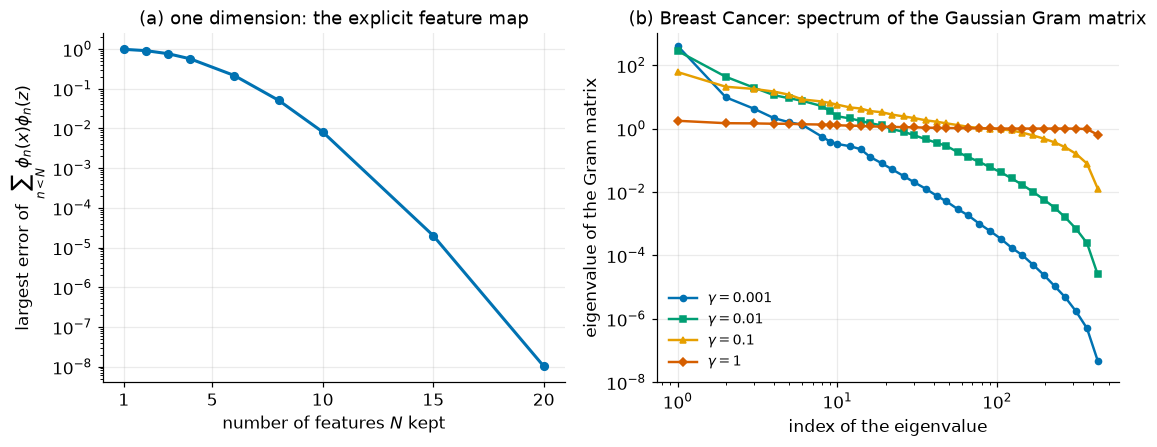

In [6]:
# Figure 9.1 — the feature space of the Gaussian kernel
def figure_9_1():
    fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.2))
    ax = axes[0]
    ax.semilogy(trunc["N"], trunc["largest error"], color=BLUE, lw=2, marker="o", ms=5)
    ax.set(xlabel="number of features $N$ kept", ylabel="largest error of $\\sum_{n<N}\\phi_n(x)\\phi_n(z)$", title="(a) one dimension: the explicit feature map")
    ax.set_xticks([1, 5, 10, 15, 20])
    ax = axes[1]
    for (g, ev), color, marker in zip(spectra.items(), [BLUE, GREEN, ORANGE, VERMILION], ["o", "s", "^", "D"]):
        idx = np.unique(np.round(np.logspace(0, np.log10(len(ev)), 40)).astype(int)) - 1
        ax.semilogy(idx + 1, np.maximum(ev[idx], 1e-16), color=color, marker=marker, ms=4, lw=1.6, label=f"$\\gamma = {g:g}$")
    ax.set_xscale("log")
    ax.set(xlabel="index of the eigenvalue", ylabel="eigenvalue of the Gram matrix", title=f"(b) Breast Cancer: spectrum of the Gaussian Gram matrix", ylim=(1e-8, 1e3))
    ax.legend(frameon=False, fontsize=9)
    fig.tight_layout()
    plt.show()


figure_9_1()

Fifteen features reproduce the Gaussian kernel on $[-2, 2]$ to $2\cdot 10^{-5}$ and twenty to $10^{-8}$: an infinite-dimensional feature map is effectively low-dimensional when the points live in a bounded region, because the damping makes the features of high degree negligible. Panel (b) says the same of real data. For $\gamma = 0.001$ only $8$ of the $426$ eigenvalues exceed $10^{-3}$ of the largest, and $98$ exceed $10^{-6}$; for $\gamma = 0.01$, $48$ and $358$; for $\gamma = 0.1$, $381$ and all $426$; for $\gamma = 1$ the matrix is close to the identity (its eigenvalues are between $0.64$ and $1.76$): the images of the $426$ patients are nearly orthogonal. **The parameter $\gamma$ sets the effective dimension of the feature space seen by the sample**, from a few smooth directions (almost linear functions) to $n$ (every patient has a direction of its own: memorization, Section 9.6).

## 9.4 The representer theorem

### 9.4.1 The space of functions behind a kernel

So far a kernel has been a way to compute inner products. The second use is as a *space of functions*, in which the learning problem can be written and solved. Let $k$ be a kernel. For each point $\mathbf{x}$, the function $k(\cdot, \mathbf{x}):\mathbf{z}\mapsto k(\mathbf{z}, \mathbf{x})$ is a function on $\mathcal{X}$ (for the Gaussian kernel, a bump of width $1/\sqrt\gamma$ centered at $\mathbf{x}$). Consider the functions that are finite combinations of such bumps, $f = \sum_{i=1}^ma_i\,k(\cdot, \mathbf{x}_i)$, with the inner product defined by bilinearity from $\langle k(\cdot, \mathbf{x}), k(\cdot, \mathbf{z})\rangle = k(\mathbf{x}, \mathbf{z})$:

$$
\Big\langle\sum_ia_ik(\cdot, \mathbf{x}_i),\ \sum_jb_jk(\cdot, \mathbf{z}_j)\Big\rangle = \sum_{i,j}a_ib_j\,k(\mathbf{x}_i, \mathbf{z}_j),
\qquad
\Big\lVert\sum_ia_ik(\cdot, \mathbf{x}_i)\Big\rVert^2 = \mathbf{a}^\top\mathbf{K}\mathbf{a}\ \ge 0 .
$$

The positivity is exactly the property of Theorem 9.1, and completing the space of these functions with respect to the norm gives a Hilbert space $\mathcal{H}_k$ of functions on $\mathcal{X}$, the **reproducing kernel Hilbert space** (RKHS) of $k$. Its name comes from the identity that evaluating $f$ at a point is an inner product with a bump:

$$
\boxed{\ f(\mathbf{x}) = \langle f,\ k(\cdot, \mathbf{x})\rangle\ }\qquad\text{(reproducing property)},
$$

which for $f = \sum_ia_ik(\cdot, \mathbf{x}_i)$ is $\sum_ia_ik(\mathbf{x}_i, \mathbf{x})$ by the definition of the inner product, and extends to the limits. Two consequences. First, $\boldsymbol\phi(\mathbf{x}) = k(\cdot, \mathbf{x})$ is a feature map of $k$ (by the definition of the inner product, $\langle\boldsymbol\phi(\mathbf{x}), \boldsymbol\phi(\mathbf{z})\rangle = k(\mathbf{x}, \mathbf{z})$), the one that completes the proof of Theorem 9.1. Second, by the Cauchy–Schwarz inequality, $\lvert f(\mathbf{x})\rvert\le\lVert f\rVert_{\mathcal{H}}\sqrt{k(\mathbf{x}, \mathbf{x})}$: *a function with a small norm is small everywhere*, and two functions with close norms and close values on the data are close elsewhere. The norm $\lVert f\rVert_{\mathcal{H}}$ is a measure of the complexity of $f$, and the kernel decides which functions are simple. For the linear kernel $\mathcal{H}_k = \{\mathbf{x}\mapsto\mathbf{w}^\top\mathbf{x}\}$ and $\lVert f\rVert_{\mathcal{H}} = \lVert\mathbf{w}\rVert$, the norm that we have penalized since Chapter 6; for the Gaussian kernel $\lVert f\rVert_{\mathcal{H}}$ penalizes high frequencies, with a weighting set by $\gamma$ (the wider the bump, the more expensive the high frequencies, hence smooth functions are cheap).

### 9.4.2 The theorem

:::{admonition} Theorem 9.4 (representer theorem; Kimeldorf and Wahba, 1971; Schölkopf, Herbrich and Smola, 2001)
:class: tip
Let $k$ be a kernel with RKHS $\mathcal{H}$, $(\mathbf{x}_i, y_i)_{i\le n}$ a training set, $L$ any function of the values $f(\mathbf{x}_1), \dots, f(\mathbf{x}_n)$ (the loss on the sample, with any dependence on the labels), and $\Omega:[0, \infty)\to\mathbb{R}$ non-decreasing. Then the problem
$$
\min_{f\in\mathcal{H}}\ L\big(f(\mathbf{x}_1), \dots, f(\mathbf{x}_n)\big) + \Omega\big(\lVert f\rVert_{\mathcal{H}}\big)
$$
has a minimizer (if it has any) of the form $f = \sum_{i=1}^n\alpha_i\,k(\cdot, \mathbf{x}_i)$. If $\Omega$ is strictly increasing, **every** minimizer has this form.
:::

:::{admonition} Proof
:class: dropdown
Let $\mathcal{S} = \operatorname{span}\{k(\cdot, \mathbf{x}_1), \dots, k(\cdot, \mathbf{x}_n)\}$, a finite-dimensional, hence closed, subspace of $\mathcal{H}$. Every $f\in\mathcal{H}$ decomposes uniquely as $f = f_\parallel + f_\perp$ with $f_\parallel\in\mathcal{S}$ and $f_\perp$ orthogonal to $\mathcal{S}$. By the reproducing property, $f(\mathbf{x}_i) = \langle f, k(\cdot, \mathbf{x}_i)\rangle = \langle f_\parallel, k(\cdot, \mathbf{x}_i)\rangle + \langle f_\perp, k(\cdot, \mathbf{x}_i)\rangle = f_\parallel(\mathbf{x}_i)$, because $k(\cdot, \mathbf{x}_i)\in\mathcal{S}$ is orthogonal to $f_\perp$. So $f$ and $f_\parallel$ have the same values on the sample, and the same loss $L$. By the Pythagorean theorem $\lVert f\rVert^2 = \lVert f_\parallel\rVert^2 + \lVert f_\perp\rVert^2\ge\lVert f_\parallel\rVert^2$, hence $\Omega(\lVert f\rVert)\ge\Omega(\lVert f_\parallel\rVert)$: replacing $f$ by $f_\parallel$ does not increase the objective, and a minimizer can be taken in $\mathcal{S}$. If $\Omega$ is strictly increasing and $f_\perp\ne 0$, the inequality is strict, so no minimizer can have $f_\perp\ne 0$. $\square$
:::

The theorem is remarkable because the problem is posed in an infinite-dimensional space and the solution lives in an $n$-dimensional one. With $f = \sum_i\alpha_ik(\cdot, \mathbf{x}_i)$ we have $f(\mathbf{x}_j) = (\mathbf{K}\boldsymbol\alpha)_j$ and $\lVert f\rVert^2_{\mathcal{H}} = \boldsymbol\alpha^\top\mathbf{K}\boldsymbol\alpha$, so the problem becomes

$$
\min_{\boldsymbol\alpha\in\mathbb{R}^n}\ L(\mathbf{K}\boldsymbol\alpha) + \Omega\big(\sqrt{\boldsymbol\alpha^\top\mathbf{K}\boldsymbol\alpha}\big),
$$

which involves the data *only through the Gram matrix*. The methods that we know are instances:

- **Ridge regression** (Chapter 6): $L = \sum_i(y_i - f(\mathbf{x}_i))^2$, $\Omega = \lambda\lVert f\rVert^2$, linear kernel; the theorem says that $\hat{\mathbf{w}}$ is a combination of the training points, Proposition 6.12.
- **The soft-margin SVM** (Chapter 8): by Proposition 8.3 the problem is $\sum_i\max\{0, 1 - y_if(\mathbf{x}_i)\} + \frac{\lambda}{2}\lVert f\rVert^2$ (with the intercept separate); the theorem gives $f = \sum_i\alpha_iy_ik(\cdot, \mathbf{x}_i)$ *a priori*, which Theorem 8.4 derived by Lagrangian duality.
- **Kernel logistic regression**: the same with the log-loss; every coefficient is non-zero (Section 8.4.1).
- **Support vector regression** (Section 8.8.2): the $\varepsilon$-insensitive loss.

*The dual forms of Chapters 6 and 8 are not accidents of those problems: every penalized method with a norm penalty in a space of functions has one.* (Without the strict monotonicity, or with a penalty that is not a function of the norm, such as the $\ell_1$ norm of Chapter 10, the theorem does not apply.)

### 9.4.3 Capacity: the margin bound in a feature space

The proof of Proposition 3.6 used only that the functions are inner products with a vector of norm at most $B$, so it applies in $\mathcal{H}$ word for word, with $\boldsymbol\phi(\mathbf{x}_i)$ in the role of $\mathbf{x}_i$.

:::{admonition} Proposition 9.5 (Rademacher complexity of a ball of the RKHS)
:class: tip
Let $\mathcal{F}_B = \{f\in\mathcal{H} : \lVert f\rVert_{\mathcal{H}}\le B\}$. The empirical Rademacher complexity on the sample $\mathbf{x}_1, \dots, \mathbf{x}_n$ satisfies
$$
\hat{\mathfrak{R}}_S(\mathcal{F}_B)\ \le\ \frac{B}{n}\sqrt{\sum_{i=1}^nk(\mathbf{x}_i, \mathbf{x}_i)}\ \le\ \frac{BR}{\sqrt n},\qquad R = \sup_{\mathbf{x}}\sqrt{k(\mathbf{x}, \mathbf{x})}.
$$
Consequently, Theorem 3.7 holds for the kernel classifiers $\operatorname{sign} f(\mathbf{x})$, $f\in\mathcal{F}_B$, with $B = \lVert f\rVert_{\mathcal{H}}$ and $R$ the radius of the images, $\sup_{\mathbf{x}}\lVert\boldsymbol\phi(\mathbf{x})\rVert$.
:::

*Proof.* With Rademacher signs $\sigma_i$, $\sum_i\sigma_if(\mathbf{x}_i) = \langle f, \sum_i\sigma_i\boldsymbol\phi(\mathbf{x}_i)\rangle\le B\big\lVert\sum_i\sigma_i\boldsymbol\phi(\mathbf{x}_i)\big\rVert$ by the Cauchy–Schwarz inequality, and by Jensen's inequality $\mathbb{E}\lVert\sum_i\sigma_i\boldsymbol\phi(\mathbf{x}_i)\rVert\le\sqrt{\mathbb{E}\lVert\sum_i\sigma_i\boldsymbol\phi(\mathbf{x}_i)\rVert^2} = \sqrt{\sum_i\lVert\boldsymbol\phi(\mathbf{x}_i)\rVert^2} = \sqrt{\sum_ik(\mathbf{x}_i, \mathbf{x}_i)}$, since the cross terms have zero mean. $\square$

The capacity of a kernel classifier does not depend on the dimension of the feature space (infinite for the Gaussian kernel) but only on $\lVert f\rVert_{\mathcal{H}}$ and on $R$. For the Gaussian kernel $R = 1$, whatever $\gamma$ and the data: no outlier inflates the radius, which was the problem with the bound of Section 8.6.1 for the linear kernel. This is the reconciliation with Chapter 3: the class of *all* functions of the RKHS has an infinite VC dimension (Section 9.3.3: any labeling of distinct points can be interpolated), but the balls $\mathcal{F}_B$ have a finite Rademacher complexity, and *the regularization parameter chooses $B$*. Section 9.6.3 evaluates the bound on a real data set.

## 9.5 Kernel ridge regression

### 9.5.1 The solution, and what it does

Take the squared loss and the penalty $\lambda\lVert f\rVert^2_{\mathcal{H}}$. The response is centered (we subtract the mean of the training responses and add it back to the predictions), as in Lemma 6.3, so that no intercept is needed. By Theorem 9.4 we look for $f = \sum_i\alpha_ik(\cdot, \mathbf{x}_i)$ and minimize $\lVert\mathbf{y} - \mathbf{K}\boldsymbol\alpha\rVert^2 + \lambda\boldsymbol\alpha^\top\mathbf{K}\boldsymbol\alpha$.

:::{admonition} Proposition 9.6 (kernel ridge regression)
:class: tip
For $\lambda > 0$ the problem $\min_{f\in\mathcal{H}}\sum_i(y_i - f(\mathbf{x}_i))^2 + \lambda\lVert f\rVert^2_{\mathcal{H}}$ has the unique solution $\hat f = \sum_i\hat\alpha_ik(\cdot, \mathbf{x}_i)$ with
$$
\hat{\boldsymbol\alpha} = (\mathbf{K} + \lambda\mathbf{I}_n)^{-1}\mathbf{y},
\qquad
\hat{\mathbf{y}} = \mathbf{K}\hat{\boldsymbol\alpha} = \mathbf{H}_\lambda\mathbf{y},\quad\mathbf{H}_\lambda = \mathbf{K}(\mathbf{K} + \lambda\mathbf{I})^{-1}.
$$
**(i)** For the linear kernel it is the ridge regression of Chapter 6. **(ii)** If $\mathbf{K} = \mathbf{U}\operatorname{diag}(\mu_1, \dots, \mu_n)\mathbf{U}^\top$ then $\hat{\mathbf{y}} = \sum_j\frac{\mu_j}{\mu_j + \lambda}(\mathbf{u}_j^\top\mathbf{y})\,\mathbf{u}_j$ and $\operatorname{df}(\lambda) = \operatorname{tr}\mathbf{H}_\lambda = \sum_j\frac{\mu_j}{\mu_j + \lambda}$. **(iii)** (leave-one-out) The prediction at $\mathbf{x}_i$ of the model fitted without example $i$, with the same $\lambda$, has the error $\dfrac{y_i - \hat y_i}{1 - (\mathbf{H}_\lambda)_{ii}}$.
:::

:::{admonition} Proof
:class: dropdown
*Solution.* The objective is $J(\boldsymbol\alpha) = \lVert\mathbf{y} - \mathbf{K}\boldsymbol\alpha\rVert^2 + \lambda\boldsymbol\alpha^\top\mathbf{K}\boldsymbol\alpha$, with gradient $-2\mathbf{K}(\mathbf{y} - \mathbf{K}\boldsymbol\alpha) + 2\lambda\mathbf{K}\boldsymbol\alpha = 2\mathbf{K}\big[(\mathbf{K} + \lambda\mathbf{I})\boldsymbol\alpha - \mathbf{y}\big]$, which vanishes at $\hat{\boldsymbol\alpha} = (\mathbf{K} + \lambda\mathbf{I})^{-1}\mathbf{y}$ ($\mathbf{K} + \lambda\mathbf{I}$ is positive definite). $J$ is convex, so this is a minimizer, and the function $\hat f$ is unique by the strict monotonicity of $\Omega(t) = \lambda t^2$ in Theorem 9.4 and the strict convexity of the problem in $\mathbf{K}\boldsymbol\alpha$. *(i)* With $\mathbf{K} = \mathbf{X}\mathbf{X}^\top$ this is the dual form of Proposition 6.12. *(ii)* $\mathbf{H}_\lambda$ and $\mathbf{K}$ have the same eigenvectors, with eigenvalues $\mu_j/(\mu_j + \lambda)$. *(iii)* Let $\hat f^{(-i)}$ be the solution without example $i$. Consider the full problem with $y_i$ replaced by $\tilde y_i = \hat f^{(-i)}(\mathbf{x}_i)$. For this modified data set, $\hat f^{(-i)}$ is still a minimizer: it minimizes the objective of the reduced problem, and the extra term $(\tilde y_i - f(\mathbf{x}_i))^2\ge 0$ vanishes at $f = \hat f^{(-i)}$. By uniqueness the fit of the modified problem is $\hat f^{(-i)}$, and since the fit is linear in the responses, $\hat f^{(-i)}(\mathbf{x}_i) = \sum_{j\ne i}(\mathbf{H}_\lambda)_{ij}y_j + (\mathbf{H}_\lambda)_{ii}\hat f^{(-i)}(\mathbf{x}_i)$. Solving, $\hat f^{(-i)}(\mathbf{x}_i) = (\hat y_i - (\mathbf{H}_\lambda)_{ii}y_i)/(1 - (\mathbf{H}_\lambda)_{ii})$, so $y_i - \hat f^{(-i)}(\mathbf{x}_i) = (y_i - \hat y_i)/(1 - (\mathbf{H}_\lambda)_{ii})$. $\square$
:::

Part (ii) is the singular-value view of Section 6.3.2, transported to the Gram matrix: *the eigenvectors of $\mathbf{K}$ with large eigenvalues (smooth functions of the data) are kept, and those with small eigenvalues (oscillating functions) are shrunk by $\mu_j/(\mu_j + \lambda)$*. Panel (b) of Figure 9.1 therefore shows what the Gaussian kernel can fit: for $\gamma = 0.001$ only a handful of directions have eigenvalues larger than a reasonable $\lambda$, and the model is nearly linear. Part (iii) is Proposition 6.8 for the kernel, and it makes the choice of $(\gamma, \lambda)$ cheap: *one* eigendecomposition per $\gamma$ gives the leave-one-out error of *every* $\lambda$, with no refit. The model with the response centered by its mean keeps the mean fixed in the leave-one-out computation, which is a very small simplification (Section 6.3.4 dealt with it in the same way).

A word about Exercise 4.8, the Nadaraya–Watson estimator $\hat f_h(x) = \sum_ik(x, x_i)y_i/\sum_ik(x, x_i)$ of Chapter 4: it is also a combination of kernel bumps centered at the training points, but its weights are *fixed by the kernel*, with no linear system to solve. It is the limiting case of kernel ridge regression in the memorization regime: when $\gamma\to\infty$, $\mathbf{K}\to\mathbf{I}$ and $\hat{\boldsymbol\alpha}\to\mathbf{y}/(1 + \lambda)$, so $\hat f(x)\to\frac1{1 + \lambda}\sum_ik(x, x_i)y_i$, the numerator of the Nadaraya–Watson estimator without its normalization (a *Parzen-window* sum). Kernel ridge regression goes further: the matrix $(\mathbf{K} + \lambda\mathbf{I})^{-1}$ discounts the redundancy between neighboring bumps, which is what makes it a good smoother with a wide kernel (small $\gamma$) where the local average of Chapter 4 would be too crude.

### 9.5.2 Checks, and a regression experiment

The cell implements kernel ridge regression from scratch and checks three claims on the Diabetes data (331 training and 111 test patients, standardized features, the split of Chapters 6 and 7): that with the linear kernel it is the `Ridge` of scikit-learn (to machine precision), that the leave-one-out formula agrees with 331 explicit refits, and that the polynomial kernel $(\mathbf{x}^\top\mathbf{z} + 1)^2$ gives the same predictions as ridge regression on the explicit features, in the case of the two features `bmi` and `s5` (six features), with the *same* coefficients $\mathbf{w} = \boldsymbol\Phi^\top\hat{\boldsymbol\alpha}$ (the representer theorem in the finite-dimensional case).

In [7]:
diab = load_diabetes()
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(diab.data, diab.target, test_size=0.25, random_state=SEED)
scaler_d = StandardScaler().fit(Xd_tr)
Zd, Zd_te = scaler_d.transform(Xd_tr), scaler_d.transform(Xd_te)
n_d = len(yd_tr)
y_mean = yd_tr.mean()
yc_d = yd_tr - y_mean                                                      # centered response


def krr_alpha(K, y, lam):
    """Dual coefficients (K + lam I)^{-1} y of kernel ridge regression."""
    return np.linalg.solve(K + lam * np.eye(len(y)), y)


def rmse(pred, y):
    return float(np.sqrt(np.mean((pred - y) ** 2)))


# (1) linear kernel = ridge regression of Chapter 6
lam = 10.0
alpha_lin = krr_alpha(Zd @ Zd.T, yc_d, lam)
pred_krr = Zd_te @ Zd.T @ alpha_lin + y_mean
pred_ridge = Ridge(alpha=lam).fit(Zd, yd_tr).predict(Zd_te)
print(f"(1) linear kernel against Ridge(alpha={lam:g}): largest difference of the test predictions {np.abs(pred_krr - pred_ridge).max():.1e}")

# (2) leave-one-out shortcut against 331 refits (RBF kernel)
K_rbf = rbf_kernel(Zd, gamma=0.02)
lam = 1.0
H = K_rbf @ np.linalg.inv(K_rbf + lam * np.eye(n_d))
loo_shortcut = (yc_d - H @ yc_d) / (1 - np.diag(H))
loo_refit = np.empty(n_d)
for i in range(n_d):
    keep = np.delete(np.arange(n_d), i)
    loo_refit[i] = yc_d[i] - K_rbf[i, keep] @ krr_alpha(K_rbf[np.ix_(keep, keep)], yc_d[keep], lam)
print(f"(2) leave-one-out errors, shortcut against {n_d} refits: largest difference {np.abs(loo_shortcut - loo_refit).max():.1e}; "
      f"LOO RMSE {np.sqrt(np.mean(loo_shortcut**2)):.2f}; effective degrees of freedom tr(H) = {np.trace(H):.1f}")

# (3) polynomial kernel against ridge on the explicit features, two features of Diabetes
cols = [list(diab.feature_names).index(c) for c in ["bmi", "s5"]]
P_tr, P_te = Zd[:, cols], Zd_te[:, cols]


def phi_poly2(X):
    x1, x2, r = X[:, 0], X[:, 1], np.sqrt(2)
    return np.c_[x1**2, x2**2, r * x1 * x2, r * x1, r * x2, np.ones(len(X))]


lam = 5.0
alpha_poly = krr_alpha((P_tr @ P_tr.T + 1) ** 2, yc_d, lam)                  # kernel (x.z + 1)^2
pred_kernel = ((P_te @ P_tr.T + 1) ** 2) @ alpha_poly + y_mean
F_tr, F_te = phi_poly2(P_tr), phi_poly2(P_te)
w_primal = np.linalg.solve(F_tr.T @ F_tr + lam * np.eye(6), F_tr.T @ yc_d)   # ridge on the 6 explicit features
print(f"(3) kernel (x.z + 1)^2 against ridge on 6 explicit features: predictions differ by {np.abs(pred_kernel - (F_te @ w_primal + y_mean)).max():.1e}; "
      f"w - Phi' alpha: {np.abs(w_primal - F_tr.T @ alpha_poly).max():.1e}; ||f||^2 = alpha' K alpha = {alpha_poly @ ((P_tr @ P_tr.T + 1) ** 2) @ alpha_poly:.3f} = ||w||^2 = {w_primal @ w_primal:.3f}")

(1) linear kernel against Ridge(alpha=10): largest difference of the test predictions 3.4e-13


(2) leave-one-out errors, shortcut against 331 refits: largest difference 1.2e-12; LOO RMSE 55.54; effective degrees of freedom tr(H) = 19.1
(3) kernel (x.z + 1)^2 against ridge on 6 explicit features: predictions differ by 3.5e-12; w - Phi' alpha: 2.7e-13; ||f||^2 = alpha' K alpha = 887.714 = ||w||^2 = 887.714


Now a regression experiment. For each $\gamma$ of a grid and each $\lambda$ we compute the leave-one-out RMSE with the shortcut (one eigendecomposition per $\gamma$), choose the best pair, and measure the test RMSE once. The linear kernel (that is, ridge regression, with its own grid of $\lambda$) is the benchmark.

In [8]:
def loo_grid(K, yc, lams):
    """Leave-one-out RMSE of kernel ridge regression for many lambdas from one eigendecomposition (Proposition 9.6)."""
    mu, U = np.linalg.eigh(K)
    uy = U.T @ yc
    out = []
    for lam in lams:
        shrink = mu / (mu + lam)
        resid = yc - U @ (shrink * uy)
        h = (U**2) @ shrink
        out.append(np.sqrt(np.mean((resid / (1 - h)) ** 2)))
    return np.array(out)


lams = 10.0 ** np.arange(-3, 4, 0.5)
gammas = [0.0003, 0.001, 0.003, 0.01, 0.03, 0.1]
rows = []
K_lin = Zd @ Zd.T
loo_lin = loo_grid(K_lin, yc_d, lams)
j = int(np.argmin(loo_lin))
alpha_ = krr_alpha(K_lin, yc_d, lams[j])
rows.append({"kernel": "linear (ridge)", "gamma": np.nan, "lambda": lams[j], "LOO RMSE": loo_lin[j], "test RMSE": rmse(Zd_te @ Zd.T @ alpha_ + y_mean, yd_te),
             "df": np.sum(np.linalg.eigvalsh(K_lin) / (np.linalg.eigvalsh(K_lin) + lams[j]))})
best = None
for g in gammas:
    K_ = rbf_kernel(Zd, gamma=g)
    loo_ = loo_grid(K_, yc_d, lams)
    j = int(np.argmin(loo_))
    mu_ = np.linalg.eigvalsh(K_)
    alpha_ = krr_alpha(K_, yc_d, lams[j])
    row = {"kernel": "Gaussian", "gamma": g, "lambda": lams[j], "LOO RMSE": loo_[j], "test RMSE": rmse(rbf_kernel(Zd_te, Zd, gamma=g) @ alpha_ + y_mean, yd_te),
           "df": np.sum(mu_ / (mu_ + lams[j]))}
    rows.append(row)
kr_table = pd.DataFrame(rows)
print(f"{n_d} training patients; best LOO RMSE of each kernel over the grid of lambda")
print(kr_table.to_string(index=False, float_format=lambda v: f"{v:.4g}"))
print(f"RMSE of the baseline that predicts the training mean: {rmse(y_mean, yd_te):.2f}")

331 training patients; best LOO RMSE of each kernel over the grid of lambda
        kernel  gamma  lambda  LOO RMSE  test RMSE    df
linear (ridge)    NaN       1      55.5      53.32 9.688
      Gaussian 0.0003   0.001     55.53      52.42 14.58
      Gaussian  0.001    0.01     55.56      52.37 14.47
      Gaussian  0.003     0.1     55.52      52.31 13.28
      Gaussian   0.01  0.3162     55.51      51.66 18.72
      Gaussian   0.03       1     55.82      51.13 25.86
      Gaussian    0.1   3.162     57.81      51.58 35.05
RMSE of the baseline that predicts the training mean: 74.88


The three checks hold to machine precision: kernel ridge regression with the linear kernel is `Ridge` ($5\cdot 10^{-13}$); the leave-one-out shortcut matches $331$ refits ($10^{-12}$; for the Gaussian kernel with $\gamma = 0.02$ and $\lambda = 1$ the leave-one-out RMSE is $55.5$, with $\operatorname{tr}\mathbf{H}_\lambda = 19.1$ effective degrees of freedom); and the polynomial kernel $(\mathbf{x}^\top\mathbf{z} + 1)^2$ produces the predictions of ridge regression on the six explicit features ($2\cdot 10^{-12}$), with $\mathbf{w} = \boldsymbol\Phi^\top\hat{\boldsymbol\alpha}$ ($5\cdot 10^{-13}$) and $\lVert f\rVert^2_{\mathcal{H}} = \hat{\boldsymbol\alpha}^\top\mathbf{K}\hat{\boldsymbol\alpha} = \lVert\mathbf{w}\rVert^2 = 887.7$. In the experiment, the leave-one-out RMSE of the Gaussian kernel is the same as that of ridge regression for every $\gamma$ from $3\cdot 10^{-4}$ to $0.01$ ($55.5$ against $55.5$), and *worse* for the larger ones ($55.8$ at $\gamma = 0.03$, $57.8$ at $0.1$): for small $\gamma$ the Gaussian kernel is nearly linear (Figure 9.1(b)), and for the larger ones it overfits. The test RMSE of the Gaussian models selected by the leave-one-out error is between $51.7$ and $52.4$, against $53.3$ for ridge, a difference of one to one and a half points of RMSE that the leave-one-out error does not see, and that $111$ test patients cannot confirm. The conclusion is the one of Section 6.7: on this data set a nonlinear kernel is not clearly better than a linear model, in spite of its larger effective number of parameters ($13$ to $19$ degrees of freedom, against $9.7$ for ridge). The baseline that predicts the mean has an RMSE of $74.9$.

### 9.5.3 The effect of the two parameters on a real regression curve

To *see* what $\gamma$ and $\lambda$ do we fit a single feature, the serum triglycerides `s5` (on a log scale, standardized), against the disease progression of the 331 training patients. We keep the penalty $\lambda = 1$ and vary the bandwidth: a small $\gamma$ gives a nearly linear curve, a moderate $\gamma$ a smooth curve with some curvature, and a large $\gamma$ a curve that follows the noise, with a leave-one-out RMSE that shows it.

In [9]:
j_s5 = list(diab.feature_names).index("s5")
x_s5 = Zd[:, [j_s5]]
grid_s5 = np.linspace(x_s5.min() - 0.1, x_s5.max() + 0.1, 300)[:, None]
panels = []
for g, lam in [(0.05, 1.0), (1.0, 1.0), (30.0, 1.0)]:
    K_ = rbf_kernel(x_s5, gamma=g)
    alpha_ = krr_alpha(K_, yc_d, lam)
    mu_ = np.linalg.eigvalsh(K_)
    fit_ = rbf_kernel(grid_s5, x_s5, gamma=g) @ alpha_ + y_mean
    panels.append({"gamma": g, "lambda": lam, "fit": fit_, "df": np.sum(mu_ / (mu_ + lam)), "loo": loo_grid(K_, yc_d, [lam])[0],
                   "train": rmse(K_ @ alpha_ + y_mean, yd_tr)})
print(pd.DataFrame([{k: v for k, v in p.items() if k != "fit"} for p in panels]).rename(columns={"df": "effective df", "loo": "LOO RMSE", "train": "training RMSE"}).to_string(index=False, float_format=lambda v: f"{v:.2f}"))

 gamma  lambda  effective df  LOO RMSE  training RMSE
  0.05    1.00          2.78     65.45          64.95
  1.00    1.00          7.46     65.89          64.55
 30.00    1.00         26.58     66.89          61.84


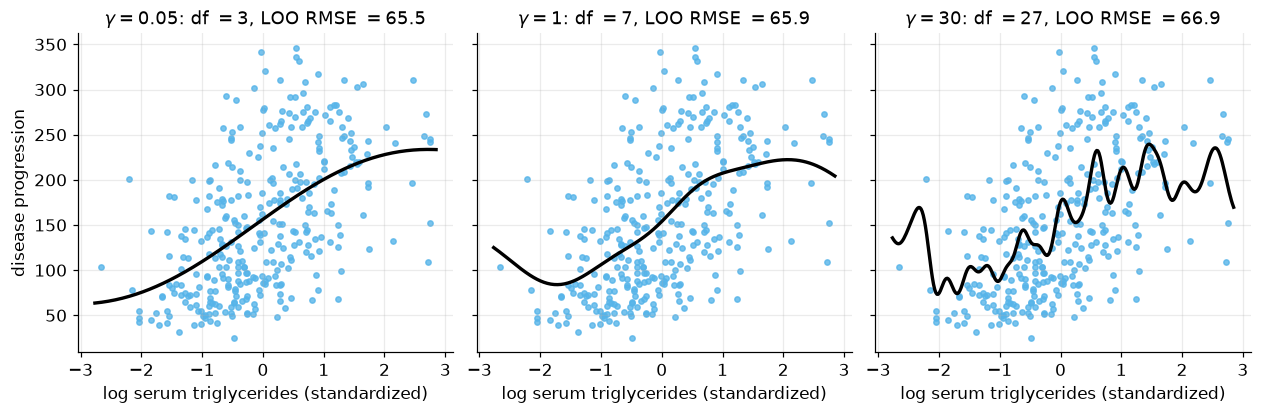

In [10]:
# Figure 9.2 — kernel ridge regression of the disease progression on one feature, for three bandwidths
def figure_9_2():
    fig, axes = plt.subplots(1, 3, figsize=(11.6, 3.9), sharey=True)
    for ax, p in zip(axes, panels):
        ax.scatter(x_s5[:, 0], yd_tr, s=12, color=SKY, alpha=0.8)
        ax.plot(grid_s5[:, 0], p["fit"], color="k", lw=2.2)
        ax.set(xlabel="log serum triglycerides (standardized)", title=f"$\\gamma = {p['gamma']:g}$: df $= {p['df']:.0f}$, LOO RMSE $= {p['loo']:.1f}$")
    axes[0].set_ylabel("disease progression")
    fig.tight_layout()
    plt.show()


figure_9_2()

With $\gamma = 0.05$ the curve is almost a straight line (about $3$ effective degrees of freedom, besides the mean). With $\gamma = 1$ it bends ($7.5$ degrees of freedom) and flattens at high values, but also turns upward at the left edge, where there are very few patients and the data cannot support it; the leave-one-out RMSE is a little worse than that of the nearly linear curve ($65.9$ against $65.5$). With $\gamma = 30$ the curve follows the noise ($26.6$ degrees of freedom): its training RMSE is the lowest of the three ($61.8$ against $64.6$ and $65.0$) and its leave-one-out RMSE the highest ($66.9$), the signature of overfitting. One feature explains little of the disease progression (all three RMSE are close to $65$, against the standard deviation of the response, $77.7$), but the lesson on the roles of the parameters is general: *$\gamma$ and $\lambda$ both control the effective number of parameters*, and so do the two together; they trade against one another (a larger $\lambda$ can compensate for a larger $\gamma$), which is why they must be chosen jointly.

## 9.6 Kernel support vector machines

### 9.6.1 The SMO of Chapter 8, unchanged

The function `smo` of Section 8.5.2 takes a Gram matrix, and nothing in it depends on how the matrix was computed: giving it the Gaussian Gram matrix instead of $\mathbf{X}\mathbf{X}^\top$ trains the kernel SVM. The prediction for a new point is $\hat f(\mathbf{x}) = \sum_i\hat\alpha_iy_i\,k(\mathbf{x}_i, \mathbf{x}) + \hat b$, a sum over the support vectors only. The cell repeats the function (so that this notebook is self-contained) and compares it with `SVC(kernel="rbf")` on the Breast Cancer training set, with $\gamma = 0.01$ and $C = 10$ (the values selected below).

In [11]:
def smo(K, y, C, tol=1e-8, max_iter=500_000):
    """Sequential minimal optimization (maximal violating pair) for the SVM dual with a Gram matrix K, labels in {-1, +1} (Section 8.5.2)."""
    n = len(y)
    alpha, G = np.zeros(n), -np.ones(n)
    for it in range(1, max_iter + 1):
        e = -y * G
        up = ((y == 1) & (alpha < C)) | ((y == -1) & (alpha > 0))
        low = ((y == 1) & (alpha > 0)) | ((y == -1) & (alpha < C))
        i = np.flatnonzero(up)[np.argmax(e[up])]
        j = np.flatnonzero(low)[np.argmin(e[low])]
        gap = e[i] - e[j]
        if gap <= tol:
            break
        a = max(K[i, i] + K[j, j] - 2 * K[i, j], 1e-12)
        t_i = (C - alpha[i]) if y[i] == 1 else alpha[i]
        t_j = alpha[j] if y[j] == 1 else (C - alpha[j])
        t = min(gap / a, t_i, t_j)
        d_i, d_j = y[i] * t, -y[j] * t
        alpha[i] += d_i
        alpha[j] += d_j
        G += (y * y[i]) * K[:, i] * d_i + (y * y[j]) * K[:, j] * d_j
    e = -y * G
    free = (alpha > 1e-10) & (alpha < C - 1e-10)
    if free.any():
        b = e[free].mean()
    else:
        up = ((y == 1) & (alpha < C)) | ((y == -1) & (alpha > 0))
        low = ((y == 1) & (alpha > 0)) | ((y == -1) & (alpha < C))
        b = (e[up].max() + e[low].min()) / 2
    return alpha, b, it


g_star, C_star = 0.01, 10.0
a_k, b_k, it_k = smo(rbf_kernel(Zb, gamma=g_star), sb, C_star, tol=1e-9)
ref_k = SVC(kernel="rbf", gamma=g_star, C=C_star, tol=1e-10).fit(Zb, yb_tr)
dec_mine = rbf_kernel(Zb_te, Zb, gamma=g_star) @ (a_k * sb) + b_k           # f(x) = sum_i alpha_i y_i k(x_i, x) + b
print(f"SMO with the Gaussian Gram matrix: {it_k} iterations, {int((a_k > 1e-9).sum())} support vectors (SVC: {len(ref_k.support_)}), "
      f"largest difference between the test decision functions {np.abs(dec_mine - ref_k.decision_function(Zb_te)).max():.1e}, "
      f"test accuracy {np.mean(np.sign(dec_mine) == sb_te):.4f}")

SMO with the Gaussian Gram matrix: 2084 iterations, 51 support vectors (SVC: 51), largest difference between the test decision functions 3.4e-06, test accuracy 0.9790


### 9.6.2 Choosing $(C, \gamma)$

The Gaussian SVM has two hyperparameters, and Chapter 5 told us how to choose them: a grid on a logarithmic scale and cross-validation on the training set, with the test set touched once. Figure 9.3 shows the 10-fold cross-validation accuracy on a grid of $C\in\{10^{-2}, \dots, 10^3\}$ and $\gamma\in\{10^{-5}, \dots, 10\}$ for the Breast Cancer training set, and the following cell reports the chosen pair, the number of support vectors, the test accuracy and two benchmarks: the linear SVM of Chapter 8 and $k$-nearest neighbors.

In [12]:
skf10 = StratifiedKFold(10, shuffle=True, random_state=SEED)
C_grid, g_grid = 10.0 ** np.arange(-2, 4), 10.0 ** np.arange(-5, 1.01, 1)
search_b = GridSearchCV(SVC(kernel="rbf", tol=1e-4), {"C": C_grid, "gamma": g_grid}, cv=skf10, scoring="accuracy").fit(Zb, yb_tr)
cv_map = search_b.cv_results_["mean_test_score"].reshape(len(C_grid), len(g_grid))        # rows: C, columns: gamma
best_b = search_b.best_estimator_
print(f"best pair of the grid: C = {search_b.best_params_['C']:g}, gamma = {search_b.best_params_['gamma']:g}; 10-fold accuracy {search_b.best_score_:.4f}; "
      f"{len(best_b.support_)} support vectors; test accuracy {best_b.score(Zb_te, yb_te):.4f} ({int((best_b.predict(Zb_te) != yb_te).sum())} errors of {len(yb_te)})")
print(f"cells of the grid within 0.005 of the best accuracy: {int((cv_map >= cv_map.max() - 0.005).sum())} of {cv_map.size}; the majority-class rate is {max(np.mean(yb_tr), 1 - np.mean(yb_tr)):.3f}")
lin_b = SVC(kernel="linear", C=0.03, tol=1e-6).fit(Zb, yb_tr)
knn_b = KNeighborsClassifier(n_neighbors=5).fit(Zb, yb_tr)
pred_rbf, pred_lin = best_b.predict(Zb_te), lin_b.predict(Zb_te)
print(f"benchmarks on the test set: linear SVM (C = 0.03, Chapter 8) {lin_b.score(Zb_te, yb_te):.4f} ({int((pred_lin != yb_te).sum())} errors); 5-NN {knn_b.score(Zb_te, yb_te):.4f}")
only_rbf, only_lin = int(((pred_rbf == yb_te) & (pred_lin != yb_te)).sum()), int(((pred_rbf != yb_te) & (pred_lin == yb_te)).sum())
print(f"patients classified correctly only by the Gaussian SVM: {only_rbf}; only by the linear SVM: {only_lin}")

best pair of the grid: C = 10, gamma = 0.01; 10-fold accuracy 0.9765; 51 support vectors; test accuracy 0.9790 (3 errors of 143)
cells of the grid within 0.005 of the best accuracy: 2 of 42; the majority-class rate is 0.627
benchmarks on the test set: linear SVM (C = 0.03, Chapter 8) 0.9790 (3 errors); 5-NN 0.9580
patients classified correctly only by the Gaussian SVM: 1; only by the linear SVM: 1


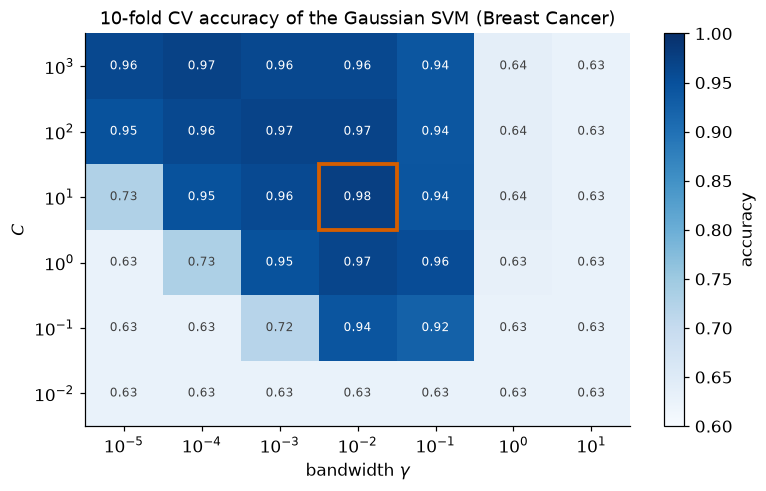

In [13]:
# Figure 9.3 — 10-fold cross-validation accuracy of the Gaussian SVM on a grid of (gamma, C), Breast Cancer
def figure_9_3():
    fig, ax = plt.subplots(figsize=(7.2, 4.6))
    im = ax.imshow(cv_map, origin="lower", cmap="Blues", vmin=0.6, vmax=1.0, aspect="auto")
    ax.set_xticks(range(len(g_grid)))
    ax.set_xticklabels([f"$10^{{{int(np.log10(g))}}}$" for g in g_grid])
    ax.set_yticks(range(len(C_grid)))
    ax.set_yticklabels([f"$10^{{{int(np.log10(c))}}}$" for c in C_grid])
    for r in range(cv_map.shape[0]):
        for c in range(cv_map.shape[1]):
            ax.text(c, r, f"{cv_map[r, c]:.2f}", ha="center", va="center", fontsize=8, color="white" if cv_map[r, c] > 0.85 else "0.25")
    r_best, c_best = np.unravel_index(np.argmax(cv_map), cv_map.shape)
    ax.add_patch(plt.Rectangle((c_best - 0.5, r_best - 0.5), 1, 1, fill=False, edgecolor=VERMILION, lw=2.5))
    ax.set(xlabel=r"bandwidth $\gamma$", ylabel="$C$", title="10-fold CV accuracy of the Gaussian SVM (Breast Cancer)")
    ax.grid(False)
    fig.colorbar(im, ax=ax, label="accuracy")
    fig.tight_layout()
    plt.show()


figure_9_3()

The $10$-fold accuracy is high in a **diagonal band** of the plane and falls to the majority-class rate ($0.63$) on the right. The band says that $C$ and $\gamma$ trade against one another: when $\gamma$ decreases by a factor of ten the best $C$ increases by about the same factor ($C = 10$ at $\gamma = 10^{-2}$, $C = 100$ to $1000$ at $\gamma = 10^{-3}$ and $10^{-4}$). A small $\gamma$ makes the Gaussian kernel nearly constant on the data, the functions of a given norm are then very small, and a large $C$ is needed to compensate; the product $C\gamma$ is roughly constant along the ridge. The best pair is $C = 10$, $\gamma = 0.01$ ($10$-fold accuracy $0.9765$, $51$ support vectors) and its test accuracy is $0.979$ ($3$ errors among $143$ patients): **the same as that of the linear SVM of Chapter 8**, which differs from it on one patient in each direction; $5$-nearest neighbors makes $6$ errors. On the Breast Cancer data, with its $30$ features, a nonlinear boundary buys nothing over a linear one, in agreement with Sections 6.7 and 8.8.1; and only $2$ of the $42$ cells of the grid are within $0.005$ of the best, so that one decade of resolution in each parameter is not much finer than needed.

The bandwidth deserves a closer look, because it moves the model through three regimes. The next cell fixes $C = 10$ and varies $\gamma$ over eight orders of magnitude, reporting the number of support vectors and the training and test accuracies; Figure 9.4 shows the decision boundaries for three values of $\gamma$ on two features, the mean radius and the mean texture of Section 8.8.1, where the picture can be drawn.

In [14]:
rows = []
for g in 10.0 ** np.arange(-5, 1.01, 1):
    m_ = SVC(kernel="rbf", gamma=g, C=10, tol=1e-4).fit(Zb, yb_tr)
    rows.append({"gamma": g, "support vectors": len(m_.support_), "training accuracy": m_.score(Zb, yb_tr), "test accuracy": m_.score(Zb_te, yb_te),
                 "predicts one class on the test set": bool(len(np.unique(m_.predict(Zb_te))) == 1)})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4g}"))

two = ["mean radius", "mean texture"]
Xk_tr, Xk_te, _, _ = train_test_split(bc.data[two].to_numpy(), yb, test_size=0.25, random_state=SEED, stratify=yb)       # the same patients as above
scaler_k = StandardScaler().fit(Xk_tr)
Zk, Zk_te = scaler_k.transform(Xk_tr), scaler_k.transform(Xk_te)

 gamma  support vectors  training accuracy  test accuracy  predicts one class on the test set
 1e-05              310             0.7535         0.7622                               False
0.0001              170             0.9531         0.9441                               False
 0.001               81             0.9789          0.965                               False
  0.01               51             0.9883          0.979                               False
   0.1              170                  1          0.951                               False
     1              426                  1         0.6294                                True
    10              426                  1         0.6294                                True


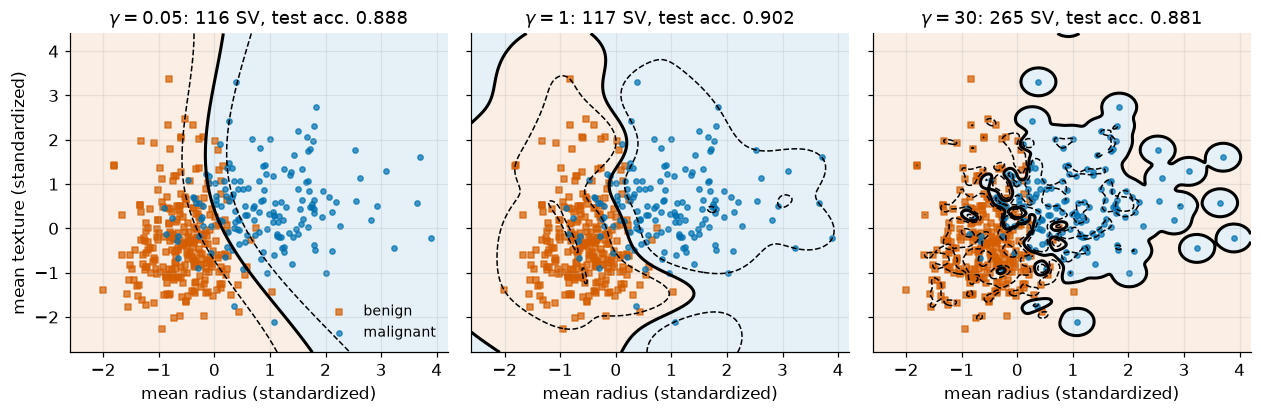

In [15]:
# Figure 9.4 — the Gaussian SVM on two features: small, moderate and large bandwidth
def figure_9_4():
    gx, gy = np.meshgrid(np.linspace(-2.6, 4.2, 240), np.linspace(-2.8, 4.4, 240))
    grid_pts = np.c_[gx.ravel(), gy.ravel()]
    fig, axes = plt.subplots(1, 3, figsize=(11.6, 3.9), sharex=True, sharey=True)
    for ax, g in zip(axes, [0.05, 1.0, 30.0]):
        m_ = SVC(kernel="rbf", gamma=g, C=10, tol=1e-6).fit(Zk, sb)
        d_ = m_.decision_function(grid_pts).reshape(gx.shape)
        ax.contourf(gx, gy, d_, levels=[-1e3, 0, 1e3], colors=[VERMILION, BLUE], alpha=0.10)
        ax.contour(gx, gy, d_, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"], linewidths=[1.0, 2.0, 1.0])
        ax.scatter(*Zk[sb == -1].T, s=12, color=VERMILION, marker="s", alpha=0.7, label="benign")
        ax.scatter(*Zk[sb == 1].T, s=12, color=BLUE, marker="o", alpha=0.7, label="malignant")
        ax.set(xlim=(-2.6, 4.2), ylim=(-2.8, 4.4), xlabel="mean radius (standardized)",
               title=f"$\\gamma = {g:g}$: {len(m_.support_)} SV, test acc. {m_.score(Zk_te, sb_te):.3f}")
    axes[0].set_ylabel("mean texture (standardized)")
    axes[0].legend(frameon=False, loc="lower right", fontsize=9)
    fig.tight_layout()
    plt.show()


figure_9_4()

The table and Figure 9.4 show the three regimes of $\gamma$. For very small $\gamma$ the model is too rigid (with $C = 10$ and $\gamma = 10^{-5}$ the accuracy is only $0.75$, because $C$ is too small to compensate, as above). Around $\gamma = 0.01$ the fit is good ($51$ support vectors, test accuracy $0.979$). For $\gamma = 0.1$ the training accuracy is already $1.000$ and the test accuracy falls to $0.951$ ($170$ support vectors). From $\gamma = 1$ on we are in the regime of **memorization**: *all* $426$ training patients are support vectors, the training accuracy is $1.000$, and the test accuracy is $0.629$, which is the proportion of benign patients in the test set: the model classifies *every* test patient as benign. The reason is the one of Section 9.3.3 (for $\gamma = 1$ the Gram matrix is almost the identity): a new patient is far from every training patient, all the $k(\mathbf{x}_i, \mathbf{x})$ are close to $0$, and the score $\hat f(\mathbf{x}) = \sum_i\hat\alpha_iy_ik(\mathbf{x}_i, \mathbf{x}) + \hat b$ reduces to the intercept $\hat b$. The same phenomenon explains the picture on two features: for $\gamma = 30$ the decision region is a set of small islands around individual patients ($265$ support vectors, test accuracy $0.881$), and for $\gamma = 1$ the corners of the plot, far from all the data, are labeled by the sign of $\hat b$ (the upper left and lower left areas are classified malignant, although there are no malignant patients there): *far from the data a Gaussian-kernel model says nothing reliable.* With $\gamma = 0.05$ the boundary is a smooth curve, and slightly better than a line ($0.888$ against $0.881$, Section 8.8.1).

### 9.6.3 The capacity bound for a kernel classifier

Proposition 9.5 says that the margin bound of Theorem 3.7 applies to the kernel SVM with $B = \lVert\hat f\rVert_{\mathcal{H}} = \sqrt{\hat{\boldsymbol\alpha}^\top\mathbf{Q}\hat{\boldsymbol\alpha}}$ (with $\hat{\boldsymbol\alpha}$ the multipliers and $\mathbf{Q} = \operatorname{diag}(\mathbf{y})\mathbf{K}\operatorname{diag}(\mathbf{y})$) and $R = 1$ for the Gaussian kernel. (As in Section 8.6.1 the intercept is ignored in $B$, which is a small simplification, and $B$ is the value found by the algorithm.) We evaluate the bound on the Breast Cancer training set, with $C = 10$ and several $\gamma$. For the linear kernel the radius $R = 19.6$ of one outlier patient made the bound of Section 8.6.1 vacuous; here $R$ is $1$ by construction, which is the point of the comparison.

In [16]:
conf_b = np.sqrt(np.log(1 / 0.05) / (2 * n_b))                              # delta = 0.05
rows = []
for g in [1e-4, 1e-3, 1e-2, 1e-1, 1.0]:
    K_ = rbf_kernel(Zb, gamma=g)
    a_, b_, _ = smo(K_, sb, 10.0, tol=1e-7)
    B = np.sqrt((a_ * sb) @ K_ @ (a_ * sb))                                  # ||f||_H
    below = np.mean(sb * (K_ @ (a_ * sb) + b_) < 1 - 1e-6)                   # fraction of training points with margin below 1
    cap = 2 * B * 1.0 / np.sqrt(n_b)                                         # R = 1 for the Gaussian kernel
    test_err = np.mean(np.sign(rbf_kernel(Zb_te, Zb, gamma=g) @ (a_ * sb) + b_) != sb_te)
    rows.append({"gamma": g, "||f||_H": B, "below margin": below, "capacity 2B/sqrt(n)": cap, "bound": below + cap + conf_b, "test error": test_err})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3f}"))

 gamma  ||f||_H  below margin  capacity 2B/sqrt(n)  bound  test error
 0.000   29.106         0.385                2.820  3.265       0.056
 0.001   19.874         0.174                1.926  2.159       0.035
 0.010   14.358         0.061                1.391  1.512       0.021
 0.100   13.073         0.005                1.267  1.331       0.049
 1.000   19.300         0.000                1.870  1.929       0.371


Near the best $\gamma$ the norm of the function is $\lVert\hat f\rVert_{\mathcal{H}} = 13$ to $14$, the capacity term $2B/\sqrt n$ is $1.3$ to $1.4$ **even with $R = 1$**, and the bound is $1.33$ to $1.51$: vacuous again, as in Section 8.6.1. The shape is more informative than the level. The bound is large for the two extremes ($3.27$ for $\gamma = 10^{-4}$, where $38\%$ of the patients are below the margin, and $1.93$ for $\gamma = 1$, where the norm grows again to $19$), and smallest at $\gamma = 0.1$ ($1.33$), where the test error is $4.9\%$, while the test error is smallest at $\gamma = 0.01$ ($2.1\%$): the bound locates the good region but not the optimum, which it puts a decade away because the fraction below the margin falls to $0.5\%$ at $\gamma = 0.1$. At $\gamma = 1$, a model that classifies every test patient as benign (test error $37\%$) has a bound of $1.93$, only slightly worse than the good ones: the bound does not see the failure either. Removing the outlier radius did not make the guarantee useful; the capacity term is dominated by $B$, which is large because the SVM with $C = 10$ pays norm for fit.

### 9.6.4 Digits: the scale of the features matters for kernels

On the Digits data (1347 training and 450 test images, the split of Chapters 6 to 8) we compare the Gaussian SVM with the linear one-vs-one SVM of Chapter 8 and, since it is the most natural reference for a kernel method, the $k$-nearest neighbors of Chapter 4. A point deserves attention: a Gaussian kernel depends on the Euclidean distance between *raw* feature vectors, so the way in which the pixels are scaled changes the kernel. We tune $(C, \gamma)$ by 5-fold cross-validation for two scalings: the standardization of Chapters 6 to 8 (each of the $64$ pixels to zero mean and unit variance), and the division of all the pixels by $16$ (the maximum), which keeps all of them on the same scale and does not amplify the pixels that are almost constant.

In [17]:
dg = load_digits()
Xg_tr, Xg_te, yg_tr, yg_te = train_test_split(dg.data, dg.target, test_size=0.25, random_state=SEED, stratify=dg.target)
skf5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
scale_std = StandardScaler().fit(Xg_tr)
versions = {"standardized pixels": (scale_std.transform(Xg_tr), scale_std.transform(Xg_te)), "pixels / 16": (Xg_tr / 16, Xg_te / 16)}
rows, preds_g = [], {}
for name, (A_tr, A_te) in versions.items():
    t0 = time.perf_counter()
    gs_ = GridSearchCV(SVC(kernel="rbf", tol=1e-4), {"C": 10.0 ** np.arange(-1, 4), "gamma": 10.0 ** np.arange(-5, 0.1, 0.5)}, cv=skf5, scoring="accuracy").fit(A_tr, yg_tr)
    preds_g[f"Gaussian SVM, {name}"] = gs_.predict(A_te)
    rows.append({"model": f"Gaussian SVM, {name}", "C": gs_.best_params_["C"], "gamma": gs_.best_params_["gamma"], "5-fold accuracy": gs_.best_score_,
                 "test accuracy": gs_.score(A_te, yg_te), "test errors": int((gs_.predict(A_te) != yg_te).sum()), "support vectors": len(gs_.best_estimator_.support_)})
A_tr, A_te = versions["standardized pixels"]
lin_g = GridSearchCV(SVC(kernel="linear", tol=1e-4), {"C": 10.0 ** np.arange(-4, 1)}, cv=skf5, scoring="accuracy").fit(A_tr, yg_tr)
preds_g["linear SVM (one-vs-one), standardized"] = lin_g.predict(A_te)
rows.append({"model": "linear SVM (one-vs-one), standardized", "C": lin_g.best_params_["C"], "gamma": np.nan, "5-fold accuracy": lin_g.best_score_,
             "test accuracy": lin_g.score(A_te, yg_te), "test errors": int((lin_g.predict(A_te) != yg_te).sum()), "support vectors": len(lin_g.best_estimator_.support_)})
knn_g = GridSearchCV(KNeighborsClassifier(), {"n_neighbors": [1, 3, 5, 7, 9]}, cv=skf5, scoring="accuracy").fit(Xg_tr / 16, yg_tr)
preds_g["k-NN, pixels / 16"] = knn_g.predict(Xg_te / 16)
rows.append({"model": "k-NN, pixels / 16", "C": np.nan, "gamma": np.nan, "5-fold accuracy": knn_g.best_score_, "test accuracy": knn_g.score(Xg_te / 16, yg_te),
             "test errors": int((knn_g.predict(Xg_te / 16) != yg_te).sum()), "support vectors": np.nan})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4g}"))
names_g = list(preds_g)
best_name = "Gaussian SVM, pixels / 16"
for other in names_g:
    if other == best_name:
        continue
    a_, b_ = preds_g[best_name] == yg_te, preds_g[other] == yg_te
    only_a, only_b = int((a_ & ~b_).sum()), int((~a_ & b_).sum())
    p_ = binomtest(min(only_a, only_b), only_a + only_b, 0.5).pvalue if only_a + only_b else 1.0
    print(f"McNemar, {best_name} against {other}: {only_a} against {only_b} discordant images, p = {p_:.3f}")

                                model    C  gamma  5-fold accuracy  test accuracy  test errors  support vectors
    Gaussian SVM, standardized pixels 1000  0.001           0.9837         0.9756           11              446
            Gaussian SVM, pixels / 16   10 0.3162           0.9911         0.9889            5              713
linear SVM (one-vs-one), standardized    1    NaN           0.9792           0.98            9              416
                    k-NN, pixels / 16  NaN    NaN           0.9881         0.9844            7              NaN
McNemar, Gaussian SVM, pixels / 16 against Gaussian SVM, standardized pixels: 7 against 1 discordant images, p = 0.070
McNemar, Gaussian SVM, pixels / 16 against linear SVM (one-vs-one), standardized: 6 against 2 discordant images, p = 0.289
McNemar, Gaussian SVM, pixels / 16 against k-NN, pixels / 16: 3 against 1 discordant images, p = 0.625


The scaling changes the result. With the standardized pixels the Gaussian SVM makes $11$ errors among the $450$ test images ($0.976$; $C = 1000$, $\gamma = 0.001$, $446$ support vectors), and with the pixels divided by $16$ it makes $5$ ($0.989$; $C = 10$, $\gamma = 0.316$, $713$ support vectors); the cross-validation accuracies, $0.984$ and $0.991$, go in the same direction. A plausible reason, which we have not tested, is that the standardization gives the same weight to the $64$ pixels, including the ones near the border of the image that are almost always zero and become huge, standardized, on the rare images where they are not, while the division by $16$ leaves the distance dominated by the informative pixels. For the models that we compare: the linear SVM of Chapter 8 makes $9$ errors, $k$-nearest neighbors on the pixels divided by $16$ makes $7$, and the softmax regression of Section 6.6 $12$. The best Gaussian SVM is a few images better than each of them, but **none of these differences is significant** (McNemar's exact $p = 0.070$ against the standardized Gaussian SVM, $0.29$ against the linear SVM and $0.63$ against $k$-NN, with $8$, $8$ and $4$ discordant images). On Digits, a data set that is nearly linearly separable and in which $k$-NN is already good, the kernel is worth a small gain at most, and the choice of the scale of the features matters at least as much as the choice of the kernel.

## 9.7 Kernel methods at scale

### 9.7.1 What a kernel method costs

The price of the kernel trick is paid in $n$. The Gram matrix has $n^2$ entries, which must be computed ($O(n^2d)$ operations for the Gaussian kernel) and stored ($8n^2$ bytes in double precision: $10{,}000$ examples need $0.8$ GB and $100{,}000$ need $80$ GB). Kernel ridge regression solves an $n\times n$ linear system, $O(n^3)$; the SMO algorithm of Section 8.5.2 takes a number of iterations that grows at least linearly with $n$, each with an $O(n)$ update, which gives between $O(n^2)$ and $O(n^3)$ in practice; and the prediction for a new point costs $O(n_{\text{SV}}\,d)$ for the SVM, $O(n\,d)$ for kernel ridge regression, since every training point is in the sum. For $n$ in the thousands this is nothing, and the exact methods are the right choice (Section 9.7.3 will show a case where the exact method is *faster* than the approximations that match it). For $n\ge 10^5$ they become impractical, and one approximates the kernel by an explicit feature map of moderate dimension $D$, then trains a *linear* model on it with the methods of Chapter 7, at a cost linear in $n$ and in $D$. Two approximations are in common use: random Fourier features, which are data-independent, and the Nyström method, which uses the data.

### 9.7.2 Random Fourier features

A classical theorem of harmonic analysis (Bochner) says that a translation-invariant kernel $k(\mathbf{x} - \mathbf{z})$ is the Fourier transform of a positive measure. For the Gaussian kernel the measure is a Gaussian, and the identity can be used as the expectation of a *random* feature: Rahimi and Recht (2007).

:::{admonition} Theorem 9.7 (random Fourier features)
:class: tip
Let $k(\mathbf{x}, \mathbf{x}') = \exp(-\gamma\lVert\mathbf{x} - \mathbf{x}'\rVert^2)$. Draw independent $\mathbf{w}_1, \dots, \mathbf{w}_D\sim\mathcal{N}(\mathbf{0}, 2\gamma\mathbf{I}_d)$ and $b_1, \dots, b_D\sim\mathrm{Uniform}[0, 2\pi]$, and set
$$
\mathbf{z}(\mathbf{x}) = \sqrt{\tfrac2D}\,\big(\cos(\mathbf{w}_j^\top\mathbf{x} + b_j)\big)_{j = 1, \dots, D}\ \in\ \mathbb{R}^D .
$$
Then **(i)** $\mathbb{E}\big[\mathbf{z}(\mathbf{x})^\top\mathbf{z}(\mathbf{x}')\big] = k(\mathbf{x}, \mathbf{x}')$; **(ii)** for every $\varepsilon > 0$, $\ \mathbb{P}\big(\lvert\mathbf{z}(\mathbf{x})^\top\mathbf{z}(\mathbf{x}') - k(\mathbf{x}, \mathbf{x}')\rvert\ge\varepsilon\big)\le 2e^{-D\varepsilon^2/8}$; **(iii)** for $m$ points, with probability at least $1 - \delta$ all the $m^2$ entries of the approximate Gram matrix are within $\varepsilon$ of the exact ones as soon as $D\ge\frac8{\varepsilon^2}\ln\frac{2m^2}{\delta}$.
:::

:::{admonition} Proof
:class: dropdown
*(i)* Write $\mathbf{z}(\mathbf{x})^\top\mathbf{z}(\mathbf{x}') = \frac1D\sum_jT_j$ with $T_j = 2\cos(\mathbf{w}_j^\top\mathbf{x} + b_j)\cos(\mathbf{w}_j^\top\mathbf{x}' + b_j) = \cos\big(\mathbf{w}_j^\top(\mathbf{x} - \mathbf{x}')\big) + \cos\big(\mathbf{w}_j^\top(\mathbf{x} + \mathbf{x}') + 2b_j\big)$. Since $b_j$ is uniform on $[0, 2\pi]$ the expectation of the second term over $b_j$ is $0$. The first has the expectation $\mathbb{E}\cos(\mathbf{w}^\top\mathbf{u}) = \operatorname{Re}\,\mathbb{E}\,e^{i\mathbf{w}^\top\mathbf{u}} = \exp\big(-\tfrac12\mathbf{u}^\top(2\gamma\mathbf{I})\mathbf{u}\big) = e^{-\gamma\lVert\mathbf{u}\rVert^2}$ for $\mathbf{u} = \mathbf{x} - \mathbf{x}'$ (the characteristic function of $\mathcal{N}(\mathbf{0}, 2\gamma\mathbf{I})$), so $\mathbb{E}\,T_j = k(\mathbf{x}, \mathbf{x}')$. *(ii)* The $T_j$ are independent with values in $[-2, 2]$ and mean $k$; Hoeffding's inequality (Section 3.5) for their average gives $\mathbb{P}(\lvert\frac1D\sum_jT_j - k\rvert\ge\varepsilon)\le 2\exp(-2D\varepsilon^2/4^2)$. *(iii)* A union bound over the $m^2$ pairs gives the failure probability $2m^2e^{-D\varepsilon^2/8}\le\delta$ under the condition on $D$. $\square$
:::

The error of a Fourier feature approximation therefore decreases like $1/\sqrt D$ whatever the dimension $d$ and the sample size, a Monte Carlo rate, and *independently of the data*. For linear models the inner product $\mathbf{z}(\mathbf{x})^\top\mathbf{z}(\mathbf{x}')$ replaces the kernel, and a linear SVM or ridge regression in $\mathbb{R}^D$ approximates the kernel one.

### 9.7.3 The Nyström method

The second approximation uses $m\ll n$ **landmark** points $\tilde{\mathbf{x}}_1, \dots, \tilde{\mathbf{x}}_m$ (a random subset of the training set) and approximates the Gram matrix of the whole sample by $\mathbf{K}\approx\mathbf{K}_{nm}\mathbf{K}_{mm}^{-1}\mathbf{K}_{mn}$, where $\mathbf{K}_{nm}$ holds the kernel values between the sample and the landmarks and $\mathbf{K}_{mm}$ those among the landmarks. It is exact if $m = n$, and in general it projects the feature space on the span of the images of the landmarks. The explicit feature map is $\mathbf{x}\mapsto\mathbf{K}_{mm}^{-1/2}\,(k(\tilde{\mathbf{x}}_j, \mathbf{x}))_{j\le m}\in\mathbb{R}^m$. It adapts to the data, and it does better than random features with the same number of components when the spectrum of the Gram matrix decays (Figure 9.1(b)).

We compare the two on Digits, with the scaling that worked (pixels divided by $16$) and the pair $(C, \gamma) = (10, 0.316)$ selected in Section 9.6.4. The cell measures, for each number of components, three errors of the approximate Gram matrix on $300$ training images (the mean and the largest absolute error of the entries, and the relative Frobenius error), and the test accuracy of a *linear* SVM trained on the explicit features (with the same $C$; the exact Gaussian SVM has $0.989$). First it checks the unbiasedness of Theorem 9.7 on one pair of images.

In [18]:
A_tr, A_te = Xg_tr / 16, Xg_te / 16
g_dig, C_dig = 10 ** -0.5, 10.0
exact_dig = SVC(kernel="rbf", gamma=g_dig, C=C_dig, tol=1e-4).fit(A_tr, yg_tr)
acc_exact = exact_dig.score(A_te, yg_te)


def random_fourier_features(X, gamma, D, seed):
    """z(x) = sqrt(2/D) cos(W'x + b), W ~ N(0, 2 gamma I), b ~ U[0, 2 pi]  (Theorem 9.7)."""
    rng = np.random.default_rng(seed)
    W = rng.normal(0.0, np.sqrt(2 * gamma), size=(X.shape[1], D))
    b = rng.uniform(0, 2 * np.pi, size=D)
    return np.sqrt(2.0 / D) * np.cos(X @ W + b)


# (i) unbiasedness and variance for one pair of images
pair = A_tr[:2]
k_pair = float(np.exp(-g_dig * np.sum((pair[0] - pair[1]) ** 2)))
est = np.array([(lambda F: F[0] @ F[1])(random_fourier_features(pair, g_dig, 50, s)) for s in range(4000)])
print(f"one pair of images, D = 50 features, 4000 draws: exact kernel {k_pair:.4f}, mean of the estimates {est.mean():.4f}, "
      f"standard deviation {est.std():.4f} (to be compared with sqrt(1/D) = {np.sqrt(1 / 50):.3f})")

sub = np.arange(300)
K_sub = rbf_kernel(A_tr[sub], gamma=g_dig)
rows = []
for D in [50, 100, 300, 1000, 3000]:
    errs, maxerrs, frob = [], [], []
    for seed in range(5):
        F_ = random_fourier_features(A_tr[sub], g_dig, D, seed)
        errs.append(np.abs(F_ @ F_.T - K_sub).mean())
        maxerrs.append(np.abs(F_ @ F_.T - K_sub).max())
        frob.append(np.linalg.norm(F_ @ F_.T - K_sub) / np.linalg.norm(K_sub))
    F_tr_, F_te_ = random_fourier_features(A_tr, g_dig, D, 0), random_fourier_features(A_te, g_dig, D, 0)
    lin_ = LinearSVC(C=C_dig, max_iter=20_000).fit(F_tr_, yg_tr)
    rows.append({"method": "random Fourier features", "components": D, "mean |error| of K": np.mean(errs), "largest |error| of K": np.mean(maxerrs), "relative Frobenius error": np.mean(frob),
                 "Hoeffding eps (delta = 0.05)": np.sqrt(8 * np.log(2 * 300**2 / 0.05) / D), "test accuracy": lin_.score(F_te_, yg_te)})
for m in [20, 50, 100, 300, 600]:
    ny = Nystroem(gamma=g_dig, n_components=m, random_state=SEED).fit(A_tr)
    F_sub = ny.transform(A_tr[sub])
    lin_ = LinearSVC(C=C_dig, max_iter=20_000).fit(ny.transform(A_tr), yg_tr)
    rows.append({"method": "Nystroem", "components": m, "mean |error| of K": np.abs(F_sub @ F_sub.T - K_sub).mean(), "largest |error| of K": np.abs(F_sub @ F_sub.T - K_sub).max(),
                 "relative Frobenius error": np.linalg.norm(F_sub @ F_sub.T - K_sub) / np.linalg.norm(K_sub), "Hoeffding eps (delta = 0.05)": np.nan, "test accuracy": lin_.score(ny.transform(A_te), yg_te)})
approx = pd.DataFrame(rows)
print(approx.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"exact Gaussian SVM: test accuracy {acc_exact:.4f}, {len(exact_dig.support_)} support vectors out of {len(yg_tr)}")

one pair of images, D = 50 features, 4000 draws: exact kernel 0.0804, mean of the estimates 0.0802, standard deviation 0.1433 (to be compared with sqrt(1/D) = 0.141)


                 method  components  mean |error| of K  largest |error| of K  relative Frobenius error  Hoeffding eps (delta = 0.05)  test accuracy
random Fourier features          50             0.1117                0.5927                    1.0033                        1.5542         0.8200
random Fourier features         100             0.0805                0.4456                    0.7231                        1.0990         0.9200
random Fourier features         300             0.0452                0.2338                    0.4063                        0.6345         0.9667
random Fourier features        1000             0.0252                0.1405                    0.2268                        0.3475         0.9800
random Fourier features        3000             0.0145                0.0754                    0.1300                        0.2006         0.9844
               Nystroem          20             0.0336                0.9898                    0.6008          

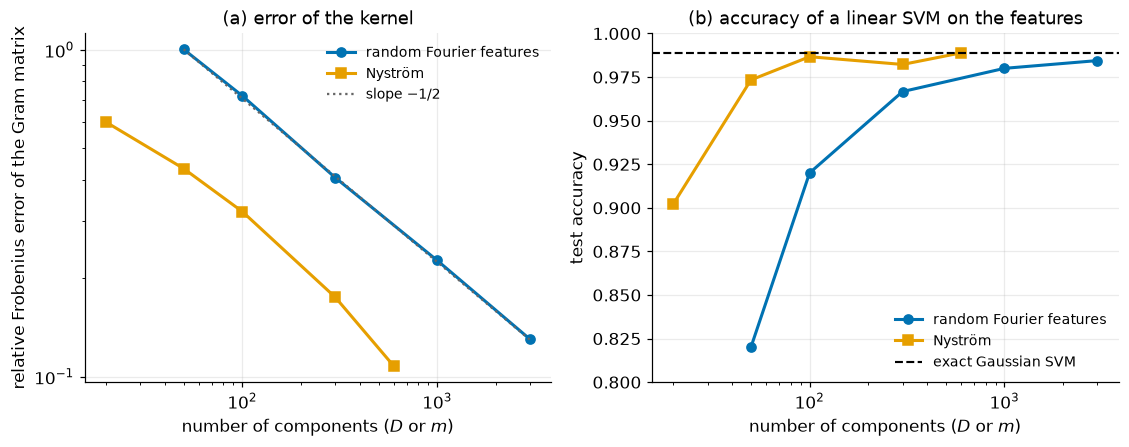

In [19]:
# Figure 9.5 — approximating the Gaussian kernel on Digits: random Fourier features and the Nystrom method
def figure_9_5():
    fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.2))
    rf, ny = approx[approx["method"] == "random Fourier features"], approx[approx["method"] == "Nystroem"]
    ax = axes[0]
    ax.loglog(rf["components"], rf["relative Frobenius error"], color=BLUE, marker="o", lw=2, label="random Fourier features")
    ax.loglog(ny["components"], ny["relative Frobenius error"], color=ORANGE, marker="s", lw=2, label="Nyström")
    kk = np.array([50, 3000])
    ax.loglog(kk, rf["relative Frobenius error"].iloc[0] * np.sqrt(kk[0] / kk), color="0.4", ls=":", lw=1.5, label=r"slope $-1/2$")
    ax.set(xlabel="number of components ($D$ or $m$)", ylabel="relative Frobenius error of the Gram matrix", title="(a) error of the kernel")
    ax.legend(frameon=False, fontsize=9)
    ax = axes[1]
    ax.semilogx(rf["components"], rf["test accuracy"], color=BLUE, marker="o", lw=2, label="random Fourier features")
    ax.semilogx(ny["components"], ny["test accuracy"], color=ORANGE, marker="s", lw=2, label="Nyström")
    ax.axhline(acc_exact, color="k", ls="--", lw=1.4, label="exact Gaussian SVM")
    ax.set(xlabel="number of components ($D$ or $m$)", ylabel="test accuracy", ylim=(0.8, 1.0), title="(b) accuracy of a linear SVM on the features")
    ax.legend(frameon=False, fontsize=9, loc="lower right")
    fig.tight_layout()
    plt.show()


figure_9_5()

Theorem 9.7 is visible in the first line: for one pair of images, with $D = 50$ features, the average of $4000$ independent estimates is $0.0802$ for an exact kernel value of $0.0804$ (unbiased), with a standard deviation of $0.143$, of the order of $\sqrt{1/D} = 0.141$. The errors of the Fourier approximation decrease like $D^{-1/2}$ (Figure 9.5(a): the relative Frobenius error goes from $1.00$ at $D = 50$ to $0.13$ at $D = 3000$, a factor $7.7 = \sqrt{60}$ for a factor $60$ in $D$), and the Hoeffding value $\varepsilon$ of the theorem, which holds with probability $0.95$ for *all* the entries at once, is conservative by a factor of about $2.5$ against the largest observed error ($0.35$ against $0.14$ at $D = 1000$). The test accuracy of the linear SVM on the Fourier features is $0.92$ with $D = 100$, $0.980$ with $D = 1000$ and $0.984$ with $D = 3000$, against $0.989$ for the exact Gaussian SVM: *about a thousand features are needed to come within one percent.* The Nyström method reaches the same accuracy with about ten times fewer components: $0.973$ with $m = 50$, $0.987$ with $m = 100$ and $0.989$ at $m = 600$, although its Gram matrix is far from exact: the relative Frobenius error is still $0.11$ at $m = 600$ and the largest entry error is large ($0.7$ to $1.0$, on the diagonal, where a low-rank matrix cannot reproduce the unit diagonal of a kernel that is almost the identity for $\gamma = 0.316$). The accuracy of the classifier needs less than an accurate Gram matrix: what matters is that the span of the features contain a good classifier. Finally, the comparison of cost deserves a warning. For $n = 1347$ the exact SVM trains faster than the approximations that match it (the Gram matrix has $1.8$ million entries): kernel approximations are for data sets with $n$ of the order of $10^5$ or more, where the exact Gram matrix cannot even be stored.

## 9.8 Designing kernels

A kernel encodes what "similar" means for the data at hand, and Proposition 9.2 gives a recipe book for building new ones from known ones, which will be valid by construction. *Sums* of kernels act on different groups of features or different views of the data (a sum of kernels is a kernel on the concatenated feature spaces); *products* combine conditions; *normalizing* $k(\mathbf{x}, \mathbf{z})/\sqrt{k(\mathbf{x}, \mathbf{x})k(\mathbf{z}, \mathbf{z})}$ gives a kernel with unit images; and the same machinery covers inputs that are not vectors (strings, graphs, trees, images), where the kernel is *the* way of introducing the knowledge about the problem (Chapter 17 and Chapter 21 will meet some of them, in the guise of convolutions and graph Laplacians).

In scikit-learn any kernel can be used with `SVC(kernel="precomputed")`: the training matrix $\mathbf{K}$ is passed to `fit`, and the matrix of the kernel values between the test and the training points to `predict`. The first thing to check is that nothing changes with a built-in kernel. The second is an illustration of Proposition 9.2 on the Breast Cancer data, whose 30 features are the *mean*, the *standard error* and the *worst value* of ten measurements: we compare the Gaussian kernel on all the features, the **sum** of three Gaussian kernels, one for each group of ten features, and their **product** (which by Proposition 9.2(ii) and the factorization of the exponential is *exactly* the Gaussian kernel on all the features, if the bandwidth is the same).

In [20]:
K_tr_pre = rbf_kernel(Zb, gamma=g_star)
pre_svc = SVC(kernel="precomputed", C=C_star, tol=1e-10).fit(K_tr_pre, yb_tr)
builtin = SVC(kernel="rbf", gamma=g_star, C=C_star, tol=1e-10).fit(Zb, yb_tr)
diff_pre = np.abs(pre_svc.decision_function(rbf_kernel(Zb_te, Zb, gamma=g_star)) - builtin.decision_function(Zb_te)).max()
print(f"precomputed kernel against the built-in Gaussian kernel: largest difference of the decision functions {diff_pre:.1e}")

groups = [slice(0, 10), slice(10, 20), slice(20, 30)]                       # mean, standard error, worst value


def k_single(A, B, g):
    return rbf_kernel(A, B, gamma=g)


def k_sum(A, B, g):
    return sum(rbf_kernel(A[:, s], B[:, s], gamma=g) for s in groups)


def k_product(A, B, g):
    return np.prod([rbf_kernel(A[:, s], B[:, s], gamma=g) for s in groups], axis=0)


rows = []
for name, kern in [("Gaussian on all 30 features", k_single), ("sum of three Gaussians (one per group)", k_sum), ("product of three Gaussians", k_product)]:
    best = None
    for g in [0.003, 0.01, 0.03, 0.1, 0.3]:
        K_ = kern(Zb, Zb, g)
        for C in [0.1, 1, 10, 100]:
            accs = []
            for tr, va in skf10.split(Zb, yb_tr):
                m_ = SVC(kernel="precomputed", C=C, tol=1e-4).fit(K_[np.ix_(tr, tr)], yb_tr[tr])
                accs.append(m_.score(K_[np.ix_(va, tr)], yb_tr[va]))
            if best is None or np.mean(accs) > best[0]:
                best = (np.mean(accs), g, C)
    acc_cv, g, C = best
    K_ = kern(Zb, Zb, g)
    final = SVC(kernel="precomputed", C=C, tol=1e-6).fit(K_, yb_tr)
    rows.append({"kernel": name, "gamma": g, "C": C, "10-fold accuracy": acc_cv, "test accuracy": final.score(kern(Zb_te, Zb, g), yb_te),
                 "smallest eigenvalue of the Gram matrix": np.linalg.eigvalsh(K_).min()})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4g}"))
g_cmp = 0.03
print(f"product kernel against the Gaussian kernel on all the features (same gamma = {g_cmp}): largest difference of the Gram matrices "
      f"{np.abs(k_product(Zb, Zb, g_cmp) - k_single(Zb, Zb, g_cmp)).max():.1e}")

precomputed kernel against the built-in Gaussian kernel: largest difference of the decision functions 5.7e-14


                                kernel  gamma  C  10-fold accuracy  test accuracy  smallest eigenvalue of the Gram matrix
           Gaussian on all 30 features   0.03  1            0.9789          0.979                               0.0005383
sum of three Gaussians (one per group)   0.03 10            0.9765          0.965                               2.574e-05
            product of three Gaussians   0.03  1            0.9789          0.979                               0.0005383
product kernel against the Gaussian kernel on all the features (same gamma = 0.03): largest difference of the Gram matrices 1.7e-15


The precomputed kernel reproduces the built-in one to $7\cdot 10^{-14}$. The experiment on the groups confirms the algebra of Proposition 9.2: **the product of the three Gaussian kernels is exactly the Gaussian kernel on the $30$ features** (the Gram matrices differ by $2\cdot 10^{-15}$, and the tuned models are identical: $10$-fold accuracy $0.9789$ and test accuracy $0.979$), because $e^{-\gamma\lVert\mathbf{x} - \mathbf{z}\rVert^2} = \prod_ge^{-\gamma\lVert\mathbf{x}_g - \mathbf{z}_g\rVert^2}$. The *sum* is a different kernel (it adds the three feature spaces instead of multiplying them: a function that is a sum of functions of the groups) and it is valid, with a positive smallest eigenvalue ($2.6\cdot 10^{-5}$), but it is not better on these data: $10$-fold accuracy $0.9765$ and test accuracy $0.965$ against $0.9789$ and $0.979$ ($2$ more errors among $143$ patients, within the noise). Prior knowledge is only useful when it is correct, and here the correct statement is that the three groups are strongly redundant (the mean and the worst value of a measurement carry nearly the same information, Section 6.2.4).

## 9.9 Summary

- **Kernels.** A kernel is an inner product in a feature space, $k(\mathbf{x}, \mathbf{z}) = \langle\boldsymbol\phi(\mathbf{x}), \boldsymbol\phi(\mathbf{z})\rangle$, and the kernel trick replaces $\mathbf{x}_i^\top\mathbf{x}_j$ by $k(\mathbf{x}_i, \mathbf{x}_j)$ in every algorithm that uses the data only through inner products: ridge regression (Proposition 6.12), the SVM (Chapter 8), and the SMO algorithm, which ran unchanged on a Gaussian Gram matrix ($2{,}094$ iterations, the $51$ support vectors of `SVC`). The kernel defines distances and angles in the feature space: $\lVert\boldsymbol\phi(\mathbf{x}) - \boldsymbol\phi(\mathbf{z})\rVert^2 = k(\mathbf{x}, \mathbf{x}) + k(\mathbf{z}, \mathbf{z}) - 2k(\mathbf{x}, \mathbf{z})$.
- **Which functions are kernels (Theorem 9.1, Proposition 9.2).** A symmetric function is a kernel if and only if all its Gram matrices are positive semidefinite; sums, products, positive scalings, polynomials with non-negative coefficients and exponentials of kernels are kernels, hence so are the polynomial and the Gaussian kernels. On the $150$ Iris flowers the Gram matrices have the ranks $4$ (linear), $35$ (cubic polynomial, $=\binom{7}{3}$) and $149$ (Gaussian: the number of distinct flowers), while $\tanh(\mathbf{x}^\top\mathbf{z})$ and the distance have $74$ and $148$ negative eigenvalues: they are not kernels. The Gaussian kernel has an infinite-dimensional feature map (explicit in one dimension: fifteen features reproduce it to $2\cdot 10^{-5}$), and its parameter $\gamma$ sets the effective dimension seen by a sample (on the $426$ Breast Cancer patients, between $8$ and $426$ eigenvalues above $10^{-3}$ of the largest).
- **The representer theorem (Theorem 9.4).** For any loss that depends on the values of $f$ on the sample and any strictly increasing penalty of $\lVert f\rVert_{\mathcal{H}}$, the minimizer over the RKHS is $f = \sum_i\alpha_ik(\cdot, \mathbf{x}_i)$, with $f(\mathbf{x}_j) = (\mathbf{K}\boldsymbol\alpha)_j$ and $\lVert f\rVert^2 = \boldsymbol\alpha^\top\mathbf{K}\boldsymbol\alpha$: an infinite-dimensional problem becomes a problem in $n$ coefficients. Ridge, SVM, logistic regression and SVR are instances. The complexity of the class is controlled by $\lVert f\rVert_{\mathcal{H}}$ and $R = \sup\sqrt{k(\mathbf{x}, \mathbf{x})}$, not by the dimension (Proposition 9.5): Theorem 3.7 applies in the feature space.
- **Kernel ridge regression (Proposition 9.6).** $\hat{\boldsymbol\alpha} = (\mathbf{K} + \lambda\mathbf{I})^{-1}\mathbf{y}$; the eigenvectors of $\mathbf{K}$ are shrunk by $\mu_j/(\mu_j + \lambda)$, the singular-value view of Chapter 6; the leave-one-out error is $e_i/(1 - H_{ii})$ (checked against $331$ refits to $10^{-12}$). On Diabetes the Gaussian kernel has the same leave-one-out RMSE as ridge ($55.5$), and a test RMSE of $51.7$ to $52.4$ against $53.3$ that the data cannot confirm.
- **Kernel SVM (Section 9.6).** $(C, \gamma)$ are tuned on a logarithmic grid by cross-validation; the good region is a diagonal band ($C\gamma$ roughly constant for small $\gamma$). The bandwidth has three regimes: nearly linear, good, and **memorization** (for $\gamma\ge 1$ on Breast Cancer all the $426$ patients are support vectors, the training accuracy is $1$ and the model classifies every test patient as benign: far from the data the score reduces to the intercept). On Breast Cancer the best Gaussian SVM ($C = 10$, $\gamma = 0.01$, test accuracy $0.979$) is as good as the linear SVM, and on Digits it makes $5$ errors in $450$ with the pixels divided by $16$ against $11$ with the standardized pixels, but no difference with the linear SVM ($9$) or $k$-NN ($7$) is significant: **the scale of the features matters for a kernel at least as much as the kernel itself.** The capacity bound is vacuous ($1.3$ to $1.5$ near the best $\gamma$, even with $R = 1$) but ranks the extremes correctly.
- **Scaling up (Section 9.7).** Gram matrix $O(n^2)$ in memory, $O(n^3)$ for kernel ridge regression. Random Fourier features are unbiased and their error decreases like $D^{-1/2}$ (Theorem 9.7); the Nyström method uses the data and needs about ten times fewer components. On Digits $1000$ Fourier features come within one percent of the exact SVM ($0.980$ against $0.989$), and $100$ Nyström landmarks are about as good ($0.987$); but at $n = 1347$ the exact method is the cheaper one: approximations pay for $n$ in the tens of thousands.
- **Designing kernels (Section 9.8).** Sums and products of kernels are kernels; a product of Gaussian kernels on groups of features with the same bandwidth is *exactly* the Gaussian kernel on all of them (difference $10^{-16}$), while a sum of kernels per group was not better than the single kernel on Breast Cancer.

### Data sources

- *Iris*: R. A. Fisher, "The use of multiple measurements in taxonomic problems", *Annals of Eugenics* 7(2), 179–188 (1936). Bundled with scikit-learn.
- *Breast Cancer Wisconsin (Diagnostic)*: W. N. Street, W. H. Wolberg and O. L. Mangasarian, "Nuclear feature extraction for breast tumor diagnosis", *IS&T/SPIE 1993 International Symposium on Electronic Imaging: Science and Technology*, volume 1905, 861–870 (1993). Bundled with scikit-learn. The target is recoded so that malignant $= +1$; the training and test sets are the stratified split of Chapters 6 to 8.
- *Digits*: E. Alpaydin and C. Kaynak, "Optical Recognition of Handwritten Digits", UCI Machine Learning Repository (1998). The test portion of the data set, 1,797 images of $8\times 8$ pixels, is bundled with scikit-learn.
- *Diabetes*: B. Efron, T. Hastie, I. Johnstone and R. Tibshirani, "Least Angle Regression", *Annals of Statistics* 32(2), 407–499 (2004). Bundled with scikit-learn.
- *Constructed data* (flagged in the text): the three points of Worked example 9.1 and the small data sets of the manual exercises. All the experiments of the chapter use the real data sets above.

### Further reading

- B. Schölkopf and A. J. Smola, *Learning with Kernels*, MIT Press, 2002. The reference on kernel methods: positive definite kernels, RKHS, the representer theorem, SVMs, kernel PCA.
- J. Shawe-Taylor and N. Cristianini, *Kernel Methods for Pattern Analysis*, Cambridge University Press, 2004. Kernels, their construction and their statistical analysis, with many examples of kernels for structured data.
- N. Aronszajn, "Theory of reproducing kernels", *Transactions of the American Mathematical Society* 68(3), 337–404 (1950). The origin of the RKHS and the Moore–Aronszajn theorem.
- G. Kimeldorf and G. Wahba, "Some results on Tchebycheffian spline functions", *Journal of Mathematical Analysis and Applications* 33(1), 82–95 (1971), and B. Schölkopf, R. Herbrich and A. J. Smola, "A generalized representer theorem", *COLT* 2001. The representer theorem in its original and in its general form (Theorem 9.4).
- C. A. Micchelli, "Interpolation of scattered data: distance matrices and conditionally positive definite functions", *Constructive Approximation* 2, 11–22 (1986). Positive definiteness of the Gaussian kernel (Section 9.3.3).
- A. Rahimi and B. Recht, "Random features for large-scale kernel machines", *Advances in Neural Information Processing Systems* 20, 2007 (Theorem 9.7), and C. K. I. Williams and M. Seeger, "Using the Nyström method to speed up kernel machines", *Advances in Neural Information Processing Systems* 13, 2001.
- C. E. Rasmussen and C. K. I. Williams, *Gaussian Processes for Machine Learning*, MIT Press, 2006 (free online). The Bayesian view of the same objects: kernel ridge regression is the posterior mean of a Gaussian process with covariance $k$ (a natural continuation of Section 6.3.5).
- M. Hein and O. Bousquet, "Kernels, associated structures and generalizations", Max Planck Institute Technical Report 127 (2004), and T. Hofmann, B. Schölkopf and A. J. Smola, "Kernel methods in machine learning", *Annals of Statistics* 36(3), 1171–1220 (2008). Surveys.
- T. Hastie, R. Tibshirani and J. Friedman, *The Elements of Statistical Learning*, 2nd ed., Springer, 2009, Chapter 5 (smoothing splines and RKHS) and Chapter 12.

## 9.10 Exercises

Difficulty: ★ warm-up, ★★ core, ★★★ challenge. Try each exercise before reading the hint; solutions and detailed outlines are in [Appendix C](../appendices/appendix_c_solutions.ipynb).

### Manual (analytical) exercises

**Exercise 9.1 ★ — Kernel or not?** For each function on $\mathbb{R}$ (or on $(0, \infty)$ where indicated) decide whether it is a kernel, with a proof or a counterexample: (a) $k(x, z) = (xz)^2$; (b) $k(x, z) = -(x - z)^2$; (c) $k(x, z) = \cos(x - z)$; (d) $k(x, z) = \max(x, z)$ on $(0, \infty)$; (e) $k(x, z) = \min(x, z)$ on $(0, \infty)$.

*Hint.* To prove that a function is a kernel, give a feature map or use Proposition 9.2; to refute it, find a $2\times 2$ Gram matrix with a negative eigenvalue or determinant. For (c) use $\cos(x - z) = \cos x\cos z + \sin x\sin z$; for (e) write $\min(x, z) = \int_0^\infty\mathbb{I}[t\le x]\,\mathbb{I}[t\le z]\,dt$.

**Exercise 9.2 ★★ — The feature space of the polynomial kernel.** (a) For $\mathbf{x}, \mathbf{z}\in\mathbb{R}^d$ and $k(\mathbf{x}, \mathbf{z}) = (\mathbf{x}^\top\mathbf{z} + c)^2$ with $c > 0$, find a feature map $\boldsymbol\phi$ such that $k = \boldsymbol\phi^\top\boldsymbol\phi$ and count its coordinates. (b) Show that the number of monomials of degree at most $p$ in $d$ variables is $\binom{d + p}{p}$, and compute it for $d = 30$ and $p = 2, 3, 5$. (c) Express $\lVert\boldsymbol\phi(\mathbf{x}) - \boldsymbol\phi(\mathbf{z})\rVert^2$ in terms of $k$, and find the cosine of the angle between $\boldsymbol\phi(\mathbf{x})$ and $\boldsymbol\phi(\mathbf{z})$ for $c = 1$, $\mathbf{x} = (1, 0)$ and $\mathbf{z} = (1, 1)$.

*Hint.* (a) Expand $(\sum_ix_iz_i + c)^2$: the squares $x_i^2z_i^2$, the cross terms $2x_ix_jz_iz_j$ for $i < j$, the terms $2c\,x_iz_i$ and the constant $c^2$. (b) Stars and bars.

**Exercise 9.3 ★★ — Kernel ridge regression by hand, and the leave-one-out shortcut.** With the kernel $k(x, z) = \min(x, z)$ and the points $x = 1, 2, 3$ with responses $\mathbf{y} = (3, 3, 5)$, $\lambda = 1$ (as in Worked example 9.1): (a) find $\hat{\boldsymbol\alpha}$ and $\hat f$; (b) compute $\lVert\hat f\rVert_{\mathcal{H}}^2$; (c) compute the three leave-one-out errors with the formula of Proposition 9.6 (iii), $\mathbf{H}_\lambda = \mathbf{I} - (\mathbf{K} + \lambda\mathbf{I})^{-1}$ in this case, and check the first by fitting the model on the two other points.

*Hint.* $(\mathbf{K} + \mathbf{I})^{-1} = \frac1{13}\begin{pmatrix}8&-2&-1\\-2&7&-3\\-1&-3&5\end{pmatrix}$. For (c), $\mathbf{K}(\mathbf{K} + \lambda\mathbf{I})^{-1} = \mathbf{I} - \lambda(\mathbf{K} + \lambda\mathbf{I})^{-1}$.

**Exercise 9.4 ★★★ — The two ends of the bandwidth.** Let $\mathbf{K}$ be the Gaussian Gram matrix of $n$ distinct points and $d_{\min} = \min_{i\ne j}\lVert\mathbf{x}_i - \mathbf{x}_j\rVert$. (a) Show by the theorem of Gershgorin that $\lambda_{\min}(\mathbf{K})\ge 1 - (n - 1)e^{-\gamma d_{\min}^2}$, so that $\mathbf{K}$ is positive definite as soon as $\gamma > \ln(n - 1)/d_{\min}^2$. (b) Deduce that as $\gamma\to\infty$ the fitted values of kernel ridge regression at the training points tend to $\mathbf{y}/(1 + \lambda)$ and the prediction at any other point tends to $0$ (the mean of the centered response). (c) Why does this explain the behavior of the Gaussian SVM for $\gamma\ge 1$ in Section 9.6.2?

*Hint.* (a) Each diagonal entry is $1$ and the off-diagonal entries of a row sum to at most $(n - 1)e^{-\gamma d_{\min}^2}$. (b) For $\gamma\to\infty$, $\mathbf{K}\to\mathbf{I}$ and $k(\mathbf{x}_i, \mathbf{x})\to 0$ for $\mathbf{x}$ not in the sample.

**Exercise 9.5 ★★ — Random Fourier features.** In one dimension, with $x = x'$: (a) show that $T = 2\cos^2(wx + b)$ has the mean $1 = k(x, x)$ and the variance $\tfrac12$ when $b\sim\mathrm{Uniform}[0, 2\pi]$; (b) how many features $D$ give a standard deviation of $0.01$ for the estimate of $k(x, x)$? (c) For $\varepsilon = 0.1$ and $\delta = 0.05$ compare the $D$ required by Chebyshev's inequality for this variance with the $D$ required by the Hoeffding bound of Theorem 9.7 (ii) for a single pair.

*Hint.* $2\cos^2\theta = 1 + \cos 2\theta$, and $2(wx + b)$ is uniform modulo $2\pi$. Chebyshev: $\mathbb{P}(\lvert\bar T - 1\rvert\ge\varepsilon)\le\operatorname{Var}(\bar T)/\varepsilon^2$.

### Python (computational) exercises

**Exercise 9.6 ★ — Testing kernels numerically.** Write a function that returns the smallest eigenvalue of a Gram matrix (symmetrized) relative to the largest one. Apply it to the first $200$ standardized patients of the Breast Cancer training set for: the linear, polynomial (degree $2$, $c = 1$), Gaussian and Laplacian kernels; the cosine similarity $\mathbf{x}^\top\mathbf{z}/(\lVert\mathbf{x}\rVert\lVert\mathbf{z}\rVert)$; $\tanh(\gamma\mathbf{x}^\top\mathbf{z} + c)$ for three values of $c$; and the histogram-intersection function $\sum_l\min(x_l, z_l)$ applied to the *non-standardized* features divided by their maxima. Which ones are kernels? For those that are not, how negative is the smallest eigenvalue?

*Hint.* `np.linalg.eigvalsh`; a relative threshold of $10^{-10}$ separates rounding errors from real negative eigenvalues. The histogram intersection is a kernel on non-negative features (it is the sum over the coordinates of $\min(x_l, z_l)$, each a kernel by Exercise 9.1(e)).

**Exercise 9.7 ★★ — Kernel ridge regression and the Laplacian kernel.** Reproduce the table of Section 9.5.2 for the Diabetes data with `loo_grid`, and repeat the experiment with the Laplacian kernel $\exp(-\gamma\lVert\mathbf{x} - \mathbf{z}\rVert_1)$ on a grid of $\gamma$. Compare the leave-one-out RMSE, the effective degrees of freedom and the test RMSE of the best Gaussian and the best Laplacian model, and check your KRR against `KernelRidge` of scikit-learn (whose `alpha` is our $\lambda$).

*Hint.* `laplacian_kernel(Z, gamma=g)`; for `KernelRidge` use `kernel="precomputed"` with `alpha=lam` and center the response yourself (`KernelRidge` has no intercept).

**Exercise 9.8 ★★ — Scale and bandwidth on Wine.** On the Wine data (`load_wine`; $178$ wines, $13$ chemical measurements, $3$ cultivars) with a stratified split of $75\%/25\%$, tune $(C, \gamma)$ of a Gaussian SVM by 5-fold cross-validation on the raw features, on the standardized features and on the features divided by their maximum, with the grid of Section 9.6.2. Draw the three cross-validation maps, and report the best pairs, the test accuracies and the number of support vectors. Explain the difference between the raw and the standardized features by the scales of the features (look at the standard deviations).

*Hint.* `StandardScaler` fitted on the training set only; the proline has a scale of hundreds and the hue of tenths.

**Exercise 9.9 ★★★ — The price of approximating.** On Digits (pixels divided by $16$), for $\gamma\in\{0.03, 0.1, 0.316\}$ (with $C = 10$), compare the exact Gaussian SVM with Nyström features and with random Fourier features for $m, D\in\{25, 50, 100, 200, 400, 800\}$: report the mean absolute error of the Gram matrix on $300$ images and the test accuracy of a linear SVM on the features. How do the two approximations depend on $\gamma$? What is the smallest number of components for which each stays within $0.5\%$ of the accuracy of the exact SVM?

*Hint.* `Nystroem(gamma=..., n_components=...)` and `RBFSampler(gamma=..., n_components=...)` of `sklearn.kernel_approximation`; a larger $\gamma$ means a more slowly decaying spectrum (Figure 9.1(b)), which is harder for the low-rank Nyström approximation.

**Exercise 9.10 ★★★ — Your own kernel.** On Digits (pixels divided by $16$), build with `sklearn.metrics.pairwise` the $\chi^2$ kernel (`chi2_kernel`) and the sum of a Gaussian and a linear kernel, check that their Gram matrices are positive semidefinite, tune $(C, \gamma)$ for each by 5-fold cross-validation with precomputed kernels, and compare their test accuracies with that of the Gaussian kernel of Section 9.6.4 by McNemar's test. Is there an advantage in a kernel designed for non-negative histograms?

*Hint.* `SVC(kernel="precomputed")`; build the training matrix once per $\gamma$ and slice it for the folds, as in Section 9.8. The $\chi^2$ kernel is $\exp(-\gamma\sum_l(x_l - z_l)^2/(x_l + z_l))$.

## What comes next

We can now fit rich nonlinear models with the machinery of convex optimization, and we know why they work: the regularization controls the norm in a feature space whose dimension does not matter. Two questions remain open in Part II. The first is **sparsity in the features**: the SVM is sparse in the *examples* (the support vectors), but its weight vector, and that of ridge, use all the coordinates; **Chapter 10** replaces the $\ell_2$ penalty by the $\ell_1$ norm, for which the representer theorem does not hold, and which sets coefficients exactly to zero (the lasso, with the proximal and coordinate methods that solve it, relatives of the algorithms of Sections 7.6 and 8.5). The second is **nonlinear models that are not based on distances**: **Chapter 11** studies decision trees and ensembles, which deal with features of any scale and with interactions without any kernel, at the cost of the convex structure; the probabilities that they produce will need the recalibration of Section 8.7.3. In Part III, **Chapter 13** returns to the Gram matrix: the eigendecomposition of the centered $\mathbf{K}$ is **kernel PCA**, and the shrinkage of the eigenvalues of Section 9.5 will be seen as a projection on the leading components. And in Part IV the *first layer* of a neural network is, in a precise sense, a randomly or adaptively chosen feature map: the random Fourier features of Section 9.7 are a two-layer network with random first-layer weights and a cosine activation, and the question that Chapters 14 and 15 will take up is what is gained by *learning* it.